# Ноутбук 3. Разложение на множители и мультипликативная группа $(\mathbb Z/n\mathbb Z)^*$

В ноутбуке 1 мы научились быстро вычислять $a^{-1}\bmod n$ и $a^e\bmod n$, в ноутбуке 2 — работать с простыми числами. Теперь соберём из этого ту алгебраическую конструкцию, в которой живут протоколы Диффи—Хеллмана, Эль-Гамаля и RSA: **группу обратимых классов вычетов** $(\mathbb Z/n\mathbb Z)^*$.

Нас интересуют четыре вопроса:

1. как разложить число на простые множители и сколько это стоит;
2. сколько элементов в группе $(\mathbb Z/n\mathbb Z)^*$ (функция Эйлера $\varphi$) и почему $\varphi(n)$ — секрет RSA;
3. что такое порядок элемента и как его найти быстро;
4. когда вся группа порождается одним элементом (первообразный корень) и почему на этом построен дискретный логарифм.

По каждой теме идём одним и тем же путём:

$$
\text{идея}\;\to\;\text{как вычисляем}\;\to\;\text{сколько это стоит}\;\to\;\text{где это в криптографии}.
$$

Стоимость, как и раньше, измеряем относительно битовой длины входа $L=\lfloor\log_2 n\rfloor+1$. Главный урок ноутбука — увидеть на своём компьютере границу между тем, что вычисляется за полиномиальное по $L$ время (степень, обратный элемент, порядок при известном разложении), и тем, что требует экспоненциального перебора (разложение $n=pq$, дискретный логарифм).

Сравнения, классы вычетов, полная система вычетов, обратный элемент и китайская теорема об остатках уже разобраны в ноутбуке 1 и здесь не повторяются: в тексте даются ссылки на соответствующие определения и формулы.

**Выполненное решение.** Задания 3.0–3.21, все практики и исследования заполнены. Запускать сверху вниз в Python-окружении курса. Цветные блоки и новые графики адаптированы для тёмной темы. Реальные времена зависят от компьютера; экстраполяции явно отделены от замеров. Сверка с SageMath выполняется только при его доступности.


<div style="background-color: #342d43; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Что появится к концу ноутбука

```text
Разложение и мультипликативные функции     Группа (Z/nZ)*
├── smallest_factor()                       class ZnZ
├── decompose(), recompose()                ├── elems(), group_order()
├── mult_function()                         ├── multiplicative_order()
├── tau, sigma                              ├── subgroup(), is_cyclic()
└── euler_phi()                             └── primitive_roots()

Быстрые алгоритмы и криптография
├── multiplicative_order_fast()
├── is_primitive_root(), primitive_root()
└── discrete_log_bruteforce()
```

В начале ноутбука (задание 3.0) в `crypto_math` переносятся `is_prime_fast`, `primes` и `next_prime` из ноутбука 2. Несколько функций этого ноутбука в конце тоже переносятся в `crypto_math`, потому что понадобятся в ноутбуках о Диффи—Хеллмане и RSA. Класс `ZnZ` остаётся учебным инструментом этого ноутбука.

</div>

### Терминология

- **разложение на простые множители** (*prime factorization*);
- **мультипликативная функция** (*multiplicative function*);
- **функция Эйлера** (*Euler's totient function*);
- **приведённая система вычетов** (*reduced residue system*);
- **порядок группы** (*order of a group*) и **порядок элемента** (*multiplicative order*);
- **циклическая группа**, **образующий элемент** (*cyclic group, generator*);
- **первообразный корень** (*primitive root*);
- **дискретный логарифм** (*discrete logarithm*);
- **безопасное простое число** (*safe prime*).

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.0. Что берём из ноутбуков 1 и 2

Чтобы не переписывать в этом ноутбуке уже готовый код, всё нужное из прошлых ноутбуков импортируем из `crypto_math`.

**Уже в библиотеке** (перенесено в ноутбуке 2 из ноутбука 1): `gcd`, `mod_inverse`, `mod_pow`, `crt`, `random_exact_bits`. Здесь они нужны для группы $(\mathbb Z/n\mathbb Z)^*$, функции Эйлера, порядка элемента и метода Полига—Хеллмана (задание 3.19).

**Переносим сейчас из ноутбука 2:**

| функция | где написана в ноутбуке 2 | где нужна в этом ноутбуке |
|---|---|---|
| `is_prime_fast(n)` | задание 3 | случайные простые `random_prime` (раздел 3.1), безопасное простое (задание 3.20) |
| `primes(n)` | задание 4 | список простых $p<10^5$ (исследование 3.6) |
| `next_prime(n)` | задание 17 | поиск безопасного простого (задание 3.20) |

Остальное из ноутбука 2 здесь не требуется: `is_prime` был учебным первым вариантом, а `isprime_list` и `prime_range` прямо не вызываются. Решето из ноутбука 2 в задании 3.2 не импортируется, а переделывается в новую функцию `omega_list`.

1. Скопируйте `is_prime_fast`, `primes` и `next_prime` в `crypto_math/number_theory.py` так же, как в ноутбуке 2 переносились функции ноутбука 1 (шаги 3–4 того ноутбука). Отладочные `print` в библиотеку не переносите.
2. Добавьте в `tests/test_number_theory.py` проверки свойств, а не отдельных значений: `is_prime_fast` и `primes` согласованы на $0\le n\le10^4$; `next_prime(n)` простое, больше $n$, и между ними простых нет.
3. Запустите `pytest -q`, перезапустите kernel и выполните ячейку ниже.

</div>

In [1]:
import math
import random
import time
from collections import Counter
from math import isqrt

from crypto_math.number_theory import (
    gcd, mod_inverse, mod_pow, crt, random_exact_bits,   # из ноутбука 1
    is_prime_fast, primes, next_prime,                   # из ноутбука 2
)

assert gcd(30, 18) == 6
assert mod_inverse(7, 23) == 10
assert mod_pow(7, 13, 23) == pow(7, 13, 23)
assert [n for n in range(50) if is_prime_fast(n)] == primes(49)
assert len(primes(10**5)) == 9592
assert next_prime(1) == 2 and next_prime(2) == 3 and next_prime(13) == 17
print("crypto_math подключена")
import secrets
from statistics import median
from itertools import combinations
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('dark_background')

crypto_math подключена


**Решение 3.0.** Функции второго ноутбука уже имеют единственную реализацию в тематическом модуле `crypto_math.primes`. В `number_theory.py` они переэкспортированы для совместимости с интерфейсом этого ноутбука: без дублирования алгоритмов и без отладочной печати. Добавлены проверки согласованности решета и проверки простоты на всём диапазоне 0…10 000, а также свойства поиска следующего простого. В заключительной ячейке выполняются все тесты и проверяется импорт из нового процесса Python.

## 3.1. Разложение на простые множители

*Материал разделов 3.1–3.2 (функции `smallest_factor`, `decompose`, `mult_function` и часть заданий) переработан из ноутбука P3wNT Notebook 4 М. Х. Вайсмана, сопровождающего книгу* An Illustrated Theory of Numbers *[7].*

### Основная теорема арифметики

Всякое натуральное $n>1$ раскладывается в произведение простых чисел, и это разложение единственно с точностью до порядка множителей:

$$
n=p_1^{e_1}p_2^{e_2}\cdots p_k^{e_k},\qquad p_1<p_2<\cdots<p_k,\quad e_i\ge1.
\tag{3.1}
$$

Запись (3.1) называется **каноническим разложением** числа $n$.

В Python каноническое разложение удобно хранить словарём: простые множители — ключи, показатели — значения. Например, $2^3\cdot3^2\cdot7$ хранится как `{2: 3, 3: 2, 7: 1}`, а числу $1$ соответствует пустой словарь `{}`.

### Как раскладываем: пробное деление

Стратегия простая: находим наименьший простой делитель $p$ числа, делим на него, записываем $p$ в словарь и повторяем, пока число не станет равным $1$.

Наименьший делитель ищем перебором. Тот же довод, что и в задании 3 ноутбука 2, позволяет остановиться на $\sqrt n$: если у $n$ нет делителя $d\le\sqrt n$, то $n$ простое. Граница вычисляется через `math.isqrt`, а после двойки перебираются только нечётные кандидаты.

In [2]:
def smallest_factor(n):
    """Целое n; минимальный простой делитель при n>=2, иначе None."""
    if n<2: return None
    if n%2==0: return 2
    for d in range(3,isqrt(n)+1,2):
        if n%d==0: return d
    return n

def decompose(N):
    """Целое N>=1; каноническое разложение {простое: положительный показатель}."""
    if N<1: raise ValueError('Разложение определено для N>=1')
    n=N; result={}
    while n>1:
        p=smallest_factor(n)
        result[p]=result.get(p,0)+1
        n//=p
    return result

print(smallest_factor(105),smallest_factor(1999**2),smallest_factor(101))
print(decompose(100))
print(decompose(56401910421778813463))
print(decompose(1))

3 1999 101
{2: 2, 5: 2}
{11: 3, 13: 9, 1999: 2}
{}


Наименьший делитель всегда прост: если бы он раскладывался как $d=ab$ с $1<a<d$, то $a$ был бы меньшим делителем $n$. Поэтому `decompose` действительно возвращает простые множители.

Заметим, что 66-битное число $56401910421778813463$ разложилось мгновенно: у него маленькие простые множители, и перебор каждый раз останавливается рано. Насколько всё меняется, когда маленьких множителей нет, покажет исследование 3.1.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.1. Обратная операция

Напишите функцию `recompose(D)`, которая восстанавливает число по словарю разложения. Проверьте, что `recompose(decompose(n)) == n` для всех $1\le n\le 10\,000$.

```python
D = decompose(1000)
print(D)
print(recompose(D))
print(recompose({2: 1, 3: 1, 5: 1, 7: 1}))
```

Ожидаемый вывод:

```text
{2: 3, 5: 3}
1000
210
```

</div>

In [3]:
def recompose(D):
    """Произведение p**e по каноническому разложению; пустой словарь даёт 1."""
    result=1
    for p,e in D.items():
        if p<2 or e<1: raise ValueError('Нужны p>=2 и e>=1')
        result*=p**e
    return result
for n in range(1,10001): assert recompose(decompose(n))==n
D=decompose(1000)
print(D); print(recompose(D)); print(recompose({2:1,3:1,5:1,7:1}))
assert recompose({})==1

{2: 3, 5: 3}
1000
210


**Ответ 3.1.** Результат — произведение простых степеней, а пустое произведение равно 1. Проверено равенство восстановления для всех 1…10 000. Каноничность ключей предполагается входным контрактом; функция восстановления не повторяет проверку простоты каждого ключа, поскольку разложение уже получено `decompose`.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.2. Сколько различных простых делителей у типичного числа

Обозначим через $\omega(n)$ число различных простых делителей $n$, то есть `len(decompose(n))`; $\omega(1)=0$.

**Гипотеза.** До вычислений предскажите: какое значение $\omega(n)$ встречается чаще всего среди $1\le n\le 10^6$? Бывают ли там числа с $\omega(n)=8$?

Найдите распределение чисел $1\le n\le10^6$ по значению $\omega(n)$ и заполните таблицу.

| $\omega(n)$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| количество $n$ | | | | | | | | |

Для самопроверки: $\omega(n)=0$ только у $n=1$, а $\omega(n)=7$ ровно у 8 чисел этого диапазона.

Напишите функцию `omega_list(n)` по алгоритму, представленному на блок-схеме.

**Вопросы.**

1. Почему $\omega(n)=8$ в этом диапазоне невозможно? Укажите наименьшее число с восемью различными простыми делителями.
2. Чем числа с $\omega(n)=1$ отличаются от простых чисел? Сравните их количество с $\pi(10^6)=78\,498$ из ноутбука 2.

*Подсказка.* Вызов `decompose` для каждого $n$ до $10^6$ займёт от нескольких секунд до минуты в зависимости от компьютера. Быстрее изменить решето Эратосфена из ноутбука 2: для каждого простого $p$ прибавлять единицу ко всем кратным $p$. Если к моменту прихода в $p$ значение `om[p]` всё ещё $0$, то $p$ простое: составное число уже получило единицу от своего меньшего простого делителя. Каждое $n$ получает по единице от каждого своего простого делителя, поэтому в конце `om[n]` $=\omega(n)$, а таблицу даёт `Counter(om[1:])`. Например, для $N=12$ список `om[1:]` равен `[0, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 2]`. Отличия от `isprime_list` из ноутбука 2: вместо вычёркивания прибавляем единицу, $p$ идёт до $N$, а не до $\sqrt N$, и кратные берутся начиная с самого $p$, а не с $p^2$.
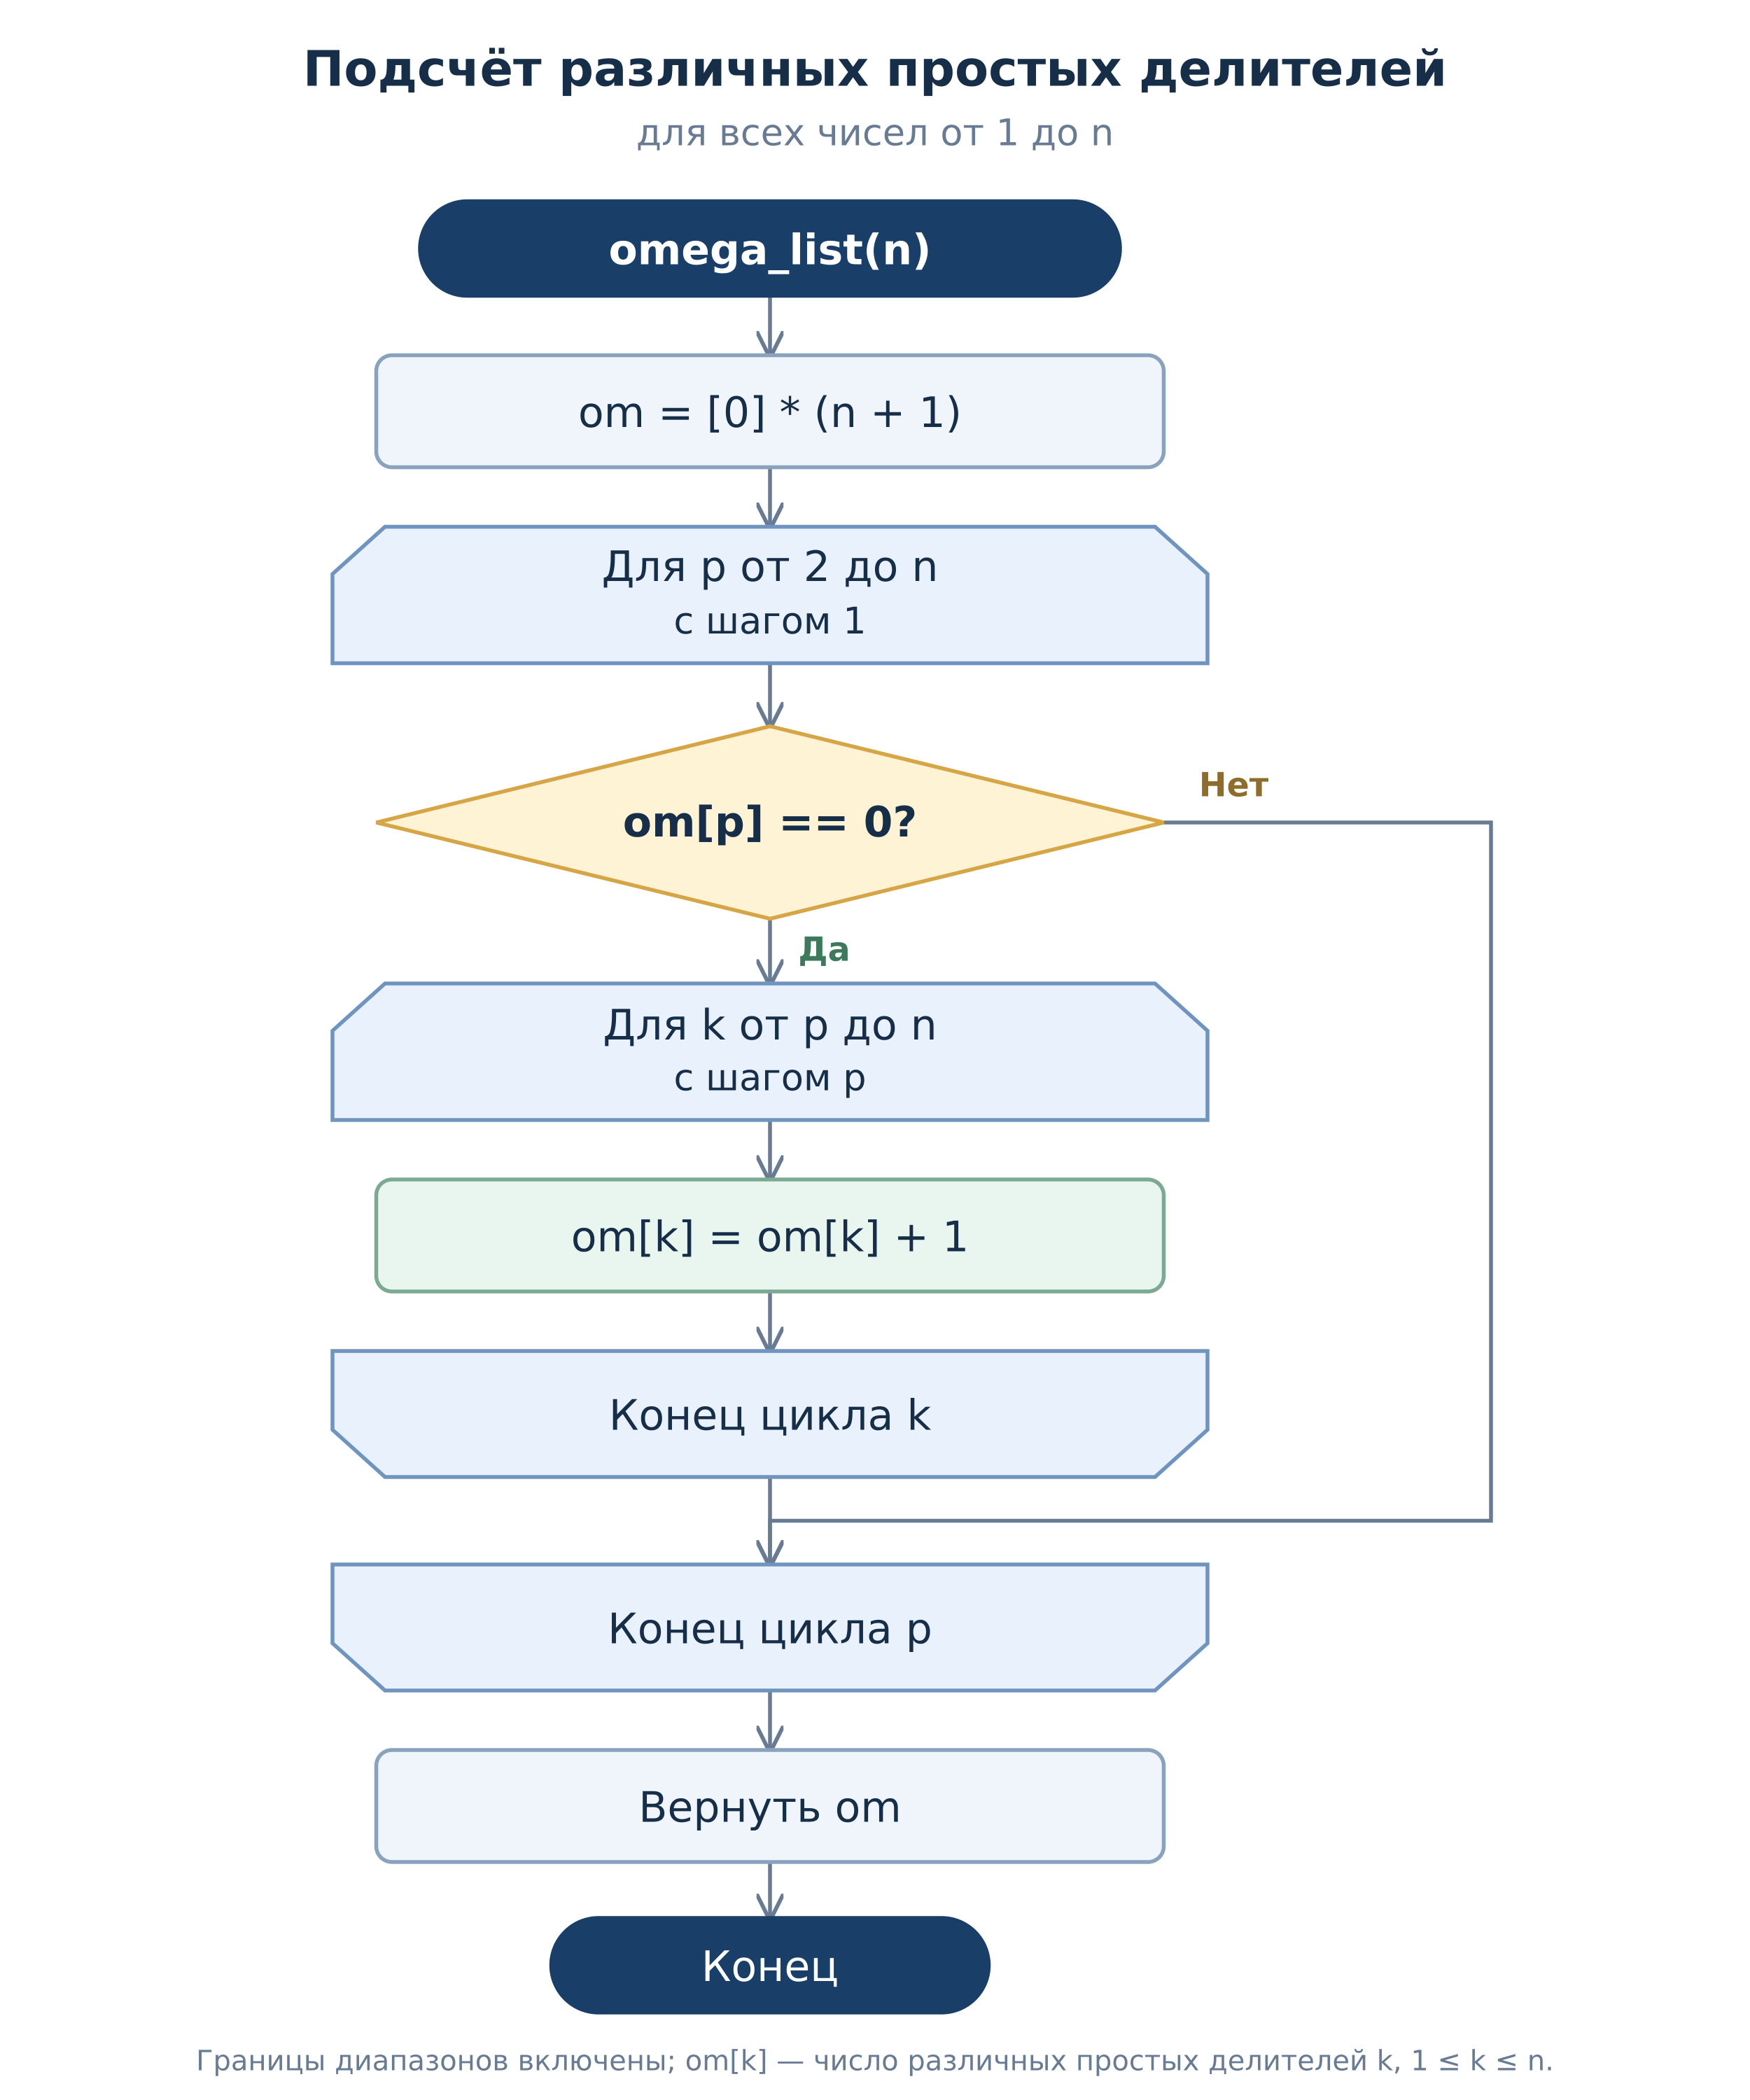
</div>

In [4]:
# Прогноз до вычисления: наиболее частое значение около 3; восемь невозможно.
def omega_list(n):
    """Целое n>=0; om[k] равно числу различных простых делителей k>=1, om[0]=0."""
    if n<0: raise ValueError('Нужен n>=0')
    om=[0]*(n+1)
    for p in range(2,n+1):
        if om[p]==0:
            for multiple in range(p,n+1,p): om[multiple]+=1
    return om
assert omega_list(12)[1:]==[0,1,1,1,1,2,1,1,1,2,1,2]
om=omega_list(10**6)
omega_counts=Counter(om[1:])
print('omega | количество')
for k in range(8): print(k,omega_counts[k])
assert omega_counts[0]==1 and omega_counts[7]==8 and max(omega_counts)==7
assert all(om[n]==len(decompose(n)) for n in range(1,2001))
print('Мода:',omega_counts.most_common(1))
minimum_eight=math.prod([2,3,5,7,11,13,17,19])
print('Наименьшее число с восемью различными простыми делителями:',minimum_eight)
print('Простых степеней сверх простых:',omega_counts[1]-78498)
del om

omega | количество
0 1
1 78734
2 288726
3 379720
4 208034
5 42492
6 2285
7 8
Мода: [(3, 379720)]
Наименьшее число с восемью различными простыми делителями: 9699690
Простых степеней сверх простых: 236


**Ответы 3.2.** При обходе простого $p$ каждому его кратному добавляется ровно единица, независимо от показателя $p$ в разложении; так получается число различных простых делителей. Составной индекс уже отмечен меньшим простым, поэтому нулевой счётчик выявляет простое. Значения таблицы и мода сохранены выше.

Наименьшее число с восемью различными простыми делителями — $2\cdot3\cdot5\cdot7\cdot11\cdot13\cdot17\cdot19=9\,699\,690>10^6$. Поэтому восемь невозможно. Значение $\omega(n)=1$ характеризует все простые степени $p^e$, а не только простые ($e=1$); точный избыток над 78 498 вычислен программой.

| ω(n) | Количество |
| --- | --- |
| 0 | 1 |
| 1 | 78734 |
| 2 | 288726 |
| 3 | 379720 |
| 4 | 208034 |
| 5 | 42492 |
| 6 | 2285 |
| 7 | 8 |

Мода — 3: 379 720 чисел. Простых степеней 78 734, на 236 больше числа простых.


Для следующих экспериментов нужны случайные простые числа заданной битовой длины. Простоту проверяем функцией `is_prime_fast` из ноутбука 2 (задание 3.0): это то же пробное деление до $\sqrt n$, что и `smallest_factor(n) == n`. Для чисел до 30–32 бит этого достаточно; быстрые тесты для больших простых появятся в ноутбуке 4.

In [5]:
def random_prime(bits):
    """Случайное нечётное простое ровно bits бит; bits>=2, учебные малые размеры."""
    if bits<2: raise ValueError('bits должно быть >=2')
    while True:
        p=random_exact_bits(bits)|1
        if is_prime_fast(p): return p
p=random_prime(24)
print(p,p.bit_length(),is_prime_fast(p))

11184539 24 True


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 3.1. Сколько стоит разложить $n=pq$

В RSA модуль $n=pq$ — произведение двух простых **одинаковой длины**. Посмотрим, как растёт время работы `decompose` на таких числах.

**Гипотеза.** Если $p\approx q\approx\sqrt n$, то `smallest_factor` перебирает около $\sqrt n/2$ нечётных кандидатов. Во сколько раз должно вырасти время, если $L$ увеличить на $4$ бита?

**Ход.** Для каждого $L$ из таблицы трижды сгенерируйте $p$ и $q$ по $L/2$ бит (`random_prime(L // 2)`), проверьте, что `(p * q).bit_length()` равно $L$ или $L-1$, замерьте время `decompose(p * q)` через `time.perf_counter()` и запишите медиану.

**Часть A. Замеры на вашем ПК.**

| $L$, бит | медиана времени, с | отношение к предыдущей строке |
|---:|---:|---:|
| 32 | | — |
| 36 | | |
| 40 | | |
| 44 | | |
| 48 | | |
| 52 | | |

**Часть B. Экстраполяция.** Время пробного деления растёт примерно как $t_0\cdot2^{L/2}$, где $t_0$ — время (в секундах) на одного кандидата-делителя. Найдите $t_0$ по последней строке таблицы и оцените время разложения 512-, 1024- и 2048-битного модуля этим методом. Переведите ответ в годы и сравните с возрастом Вселенной (около $4\cdot10^{17}$ с).

**Вопросы.**

1. Совпало ли наблюдаемое отношение с вашей гипотезой?
2. Почему число $56401910421778813463$ из примера выше разложилось мгновенно, хотя оно длиннее всех чисел таблицы? Какие простые $p,q$ поэтому нельзя брать в RSA?
3. Пробное деление — самый простой, но не лучший метод (обзор методов — [3, §2.3, с. 228–254]; пробное деление — [3, §2.3.2, с. 232], [5, §14.1, с. 319]; число пробных делений на примере — [6, табл. 3.2, с. 50–51]). Лучшие известные алгоритмы разложения работают быстрее любой экспоненты $2^{cL}$, но всё же не полиномиально по $L$. Почему криптографу важно именно это различие, а не скорость конкретной реализации?

</div>

L | три измерения, с | медиана, с | отношение
32 [0.0016292000655084848, 0.001543200109153986, 0.0016302999574691057] 0.0016292000655084848 None
36 [0.004264599992893636, 0.0041120999958366156, 0.0028719999827444553] 0.0041120999958366156 2.5239994049185115
40 [0.017671599984169006, 0.02264589990954846, 0.012231500004418194] 0.017671599984169006 4.297463583585272


44 [0.047028500004671514, 0.056006800034083426, 0.0715425000526011] 0.056006800034083426 3.1693112159768653


48 [0.2944200999336317, 0.31324649997986853, 0.2526882999809459] 0.2944200999336317 5.256863447910964


52 [0.7508201999589801, 0.9723341999342665, 0.7056186000118032] 0.7508201999589801 2.5501662424821885
Коэффициент C = 1.1188092827185692e-08 с; оценка времени кандидата = 4.189906794915069e-08 с
L | log10(лет) | log10(время / возраст Вселенной)
512 61.61333098393339 51.51037495969065
1024 138.67700987391257 128.57405384966984
2048 292.804367653871 282.70141162962824


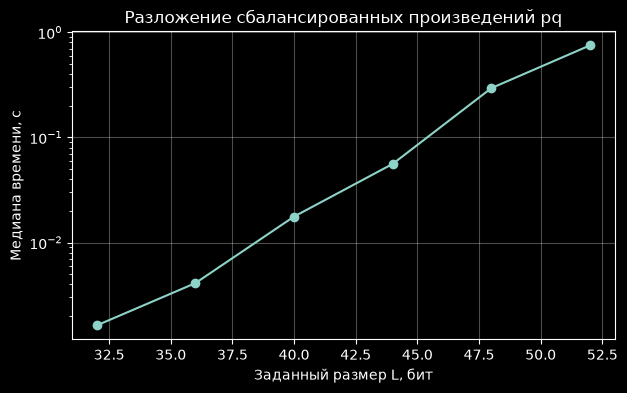

In [6]:
# Прогноз: добавление 4 бит увеличивает число пробных делителей примерно в 4 раза.
factor_timings=[]; factor_samples={}
previous=None
print('L | три измерения, с | медиана, с | отношение')
for L in (32,36,40,44,48,52):
    samples=[]; records=[]
    for _ in range(3):
        p,q=random_prime(L//2),random_prime(L//2)
        while q==p: q=random_prime(L//2)
        n=p*q
        assert n.bit_length() in (L,L-1)
        start=time.perf_counter(); D=decompose(n); elapsed=time.perf_counter()-start
        assert D==dict(sorted({p:1,q:1}.items())) and recompose(D)==n
        samples.append(elapsed); records.append((p,q,n,elapsed))
    current=median(samples)
    factor_timings.append((L,current));factor_samples[L]=records
    print(L,samples,current,None if previous is None else current/previous)
    previous=current

# t(L)=C*2**(L/2): C включает постоянные и распределение размера множителей.
factor_C=factor_timings[-1][1]/2**(52/2)
# Более буквальная оценка времени проверки одного нечётного кандидата.
candidate_seconds=median(t/(min(p,q)//2) for p,q,n,t in factor_samples[52])
print('Коэффициент C =',factor_C,'с; оценка времени кандидата =',candidate_seconds,'с')
print('L | log10(лет) | log10(время / возраст Вселенной)')
for L in (512,1024,2048):
    log_seconds=math.log10(factor_C)+(L/2)*math.log10(2)
    print(L,log_seconds-math.log10(365.25*86400),log_seconds-math.log10(4*10**17))
fig,ax=plt.subplots(figsize=(7,4))
ax.semilogy([r[0] for r in factor_timings],[r[1] for r in factor_timings],'o-')
ax.set(xlabel='Заданный размер L, бит',ylabel='Медиана времени, с',title='Разложение сбалансированных произведений pq')
ax.grid(alpha=.3);plt.show()

**Ответы исследования 3.1.** Для множителей примерно по $L/2$ бит число кандидатов имеет порядок $2^{L/2}$, поэтому прогноз отношения при $L\to L+4$ — 4. Случайный размер меньшего множителя, фактические $L$ или $L-1$ бит произведения и шум времени дают отклонения; таблица содержит именно измеренные отношения. $C=t_{52}/2^{26}$ — коэффициент экстраполяции модели, тогда как буквальная стоимость одного нечётного деления оценена отдельно: в модели $2^{L/2}$ опущены постоянные множители. Для огромных времён выведены десятичные логарифмы: значение 100 в колонке лет означает примерно $10^{100}$ лет. Это оценки пробного деления, не измерения и не оценка лучшей атаки на RSA.

У 66-битного примера малы простые делители 11, 13 и 1999, поэтому алгоритм быстро их находит; битовой длины самой по себе недостаточно для оценки конкретного входа. В RSA нельзя выбирать маленький простой множитель или сильно несбалансированную пару. Субэкспоненциальный и полиномиальный рост — разные зависимости от размера входа: криптографические параметры оценивают по лучшим применимым атакам, а не только по скорости нашего пробного деления.

| L, бит | Медиана, с | Отношение |
| --- | --- | --- |
| 32 | 0.0016292 | — |
| 36 | 0.0041121 | 2.524 |
| 40 | 0.0176716 | 4.29746 |
| 44 | 0.0560068 | 3.16931 |
| 48 | 0.29442 | 5.25686 |
| 52 | 0.75082 | 2.55017 |

По замерам рост не равен ровно 4 на каждой строке, но общий масштаб соответствует экспоненциальному прогнозу.


## 3.2. Мультипликативные функции

Разложение (3.1) полезно не только само по себе: по нему быстро вычисляются целые семейства арифметических функций. Нам понадобится одна из них — функция Эйлера, — но сначала посмотрим на общий приём на двух более простых примерах.

### Определение 3.1. Мультипликативная функция

Функция $f:\mathbb N\to\mathbb Z$ называется **мультипликативной**, если $f(1)=1$ и

$$
f(mn)=f(m)\,f(n)\qquad\text{для всех взаимно простых } m,n.
\tag{3.2}
$$

Если $n$ имеет разложение (3.1), то множители $p_i^{e_i}$ попарно взаимно просты, и из (3.2) следует

$$
f(n)=f\bigl(p_1^{e_1}\bigr)\,f\bigl(p_2^{e_2}\bigr)\cdots f\bigl(p_k^{e_k}\bigr).
\tag{3.3}
$$

Значит, мультипликативную функцию достаточно знать на степенях простых чисел. Именно это и делает функция `mult_function`: по правилу `f_pp(p, e)` для $f(p^e)$ она строит функцию $f(n)$ для любого $n$. Подробнее о мультипликативных функциях, $\tau$ и $\sigma$ — [3, §1.4.1–1.4.2, с. 63–69], [4, §7.1–7.2, с. 239–253]; реализация через разложение пробным делением — [6, §3.3–3.4, с. 64–69].

In [7]:
def mult_function(f_pp):
    '''
    По функции f_pp(p, e), задающей значения f(p**e),
    возвращает мультипликативную функцию f(n), вычисляемую по формуле (3.3).
    '''
    def f(n):
        result = 1
        for p, e in decompose(n).items():
            result *= f_pp(p, e)
        return result
    return f

### Два примера: число и сумма делителей

Обозначим

$$
\tau(n)=\#\{d\ge1:\ d\mid n\},\qquad \sigma(n)=\sum_{d\mid n,\ d\ge1} d.
\tag{3.4}
$$

Обе функции мультипликативны, поэтому их достаточно вычислить для степеней простых. Делители числа $p^e$ — это $1,p,\ldots,p^e$: их $e+1$ штук, а их сумма — геометрическая прогрессия:

$$
\tau(p^e)=e+1,\qquad \sigma(p^e)=1+p+\cdots+p^e=\frac{p^{e+1}-1}{p-1}.
\tag{3.5}
$$

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.3. $\tau$ и $\sigma$ через разложение

1. Напишите `tau_pp(p, e)` и `sigma_pp(p, e)` по формулам (3.5) и получите `tau = mult_function(tau_pp)`, `sigma = mult_function(sigma_pp)`. В `sigma_pp` используйте целочисленное деление `//`.
2. Напишите «наивные» версии `tau_naive(n)` и `sigma_naive(n)`, которые перебирают все $d$ от $1$ до $n$.
3. Проверьте совпадение двух версий для всех $1\le n\le 2000$.

```python
print(tau(100), sigma(28), sigma(1))
```

Ожидаемый вывод: `9 56 1`.

</div>

In [8]:
def tau_pp(p,e): return e+1
def sigma_pp(p,e): return (p**(e+1)-1)//(p-1)
tau=mult_function(tau_pp)
sigma=mult_function(sigma_pp)
def tau_naive(n):
    if n<1: raise ValueError('n>=1')
    return sum(n%d==0 for d in range(1,n+1))
def sigma_naive(n):
    if n<1: raise ValueError('n>=1')
    return sum(d for d in range(1,n+1) if n%d==0)
for n in range(1,2001):
    assert tau(n)==tau_naive(n) and sigma(n)==sigma_naive(n)
print(tau(100),sigma(28),sigma(1))

9 56 1


**Ответ 3.3.** Делитель $p^e$ имеет вид $p^j$, $j=0,\ldots,e$, поэтому число делителей $e+1$, а сумма — геометрическая прогрессия $(p^{e+1}-1)/(p-1)$. Для взаимно простых простых степеней выбор показателей независим, поэтому результаты перемножаются. Деление `//` точно: числитель делится на знаменатель. Обе версии совпали на всех 1…2000.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.4. Где нужна взаимная простота

1. Проверьте равенство $\sigma(mn)=\sigma(m)\sigma(n)$ для **всех** пар взаимно простых $1\le m,n\le100$.
2. Найдите пару $m,n\le10$, не взаимно простых, для которой равенство нарушается. Объясните, какие делители числа $mn$ «теряются» или «считаются дважды».
3. *(Дополнительно.)* Пусть $f(n)$ — число делителей $n$, не делящихся на $4$. Например, у $60$ таких делителей 8 ($1,2,3,5,6,10,15,30$), у $144$ — шесть. Найдите $f(p^e)$ для $p=2$ и для нечётного $p$ и реализуйте $f$ через `mult_function`.

</div>

In [9]:
for m in range(1,101):
    for n in range(1,101):
        if gcd(m,n)==1: assert sigma(m*n)==sigma(m)*sigma(n)
counterexample=next((m,n,sigma(m*n),sigma(m)*sigma(n)) for m in range(1,11) for n in range(1,11) if gcd(m,n)>1 and sigma(m*n)!=sigma(m)*sigma(n))
print('Контрпример m,n,sigma(mn),sigma(m)sigma(n):',counterexample)
def no_four_pp(p,e): return min(e+1,2) if p==2 else e+1
no_four=mult_function(no_four_pp)
assert no_four(60)==8 and no_four(144)==6
for n in range(1,501):
    assert no_four(n)==sum(n%d==0 and d%4!=0 for d in range(1,n+1))
print('Дополнительная функция:',no_four(60),no_four(144))

Контрпример m,n,sigma(mn),sigma(m)sigma(n): (2, 2, 7, 9)
Дополнительная функция: 8 6


**Ответ 3.4.** Например, $m=n=2$: $\sigma(4)=1+2+4=7$, а $\sigma(2)^2=(1+2)^2=9$. Разные пары делителей (1,2) и (2,1) порождают один и тот же делитель 2, который считается дважды. При взаимной простоте такое разложение делителя единственно. В дополнительном задании показатель двойки в допустимом делителе равен 0 или 1: $f(2^e)=\min(e+1,2)$; для нечётного $p$ ограничений нет, $f(p^e)=e+1$.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика 3.2. По определению или по разложению

**Гипотеза.** Что быстрее для $n\approx10^7$: `sigma_naive(n)` или `sigma(n)`? Во сколько раз, по вашей оценке?

Замерьте время обеих версий для нескольких $n$ и заполните таблицу.

| $n$ | `sigma_naive`, с | `sigma`, с |
|---:|---:|---:|
| $10^4$ | | |
| $10^5$ | | |
| $10^6$ | | |
| $10^7$ | | |
| $2^{60}$ | — | |
| $p\cdot q$, $p,q$ по 26 бит | — | |

**Вопросы.**

1. Сколько шагов делает каждая версия как функция от $n$, а затем от $L$?
2. Почему `sigma` мгновенна на $2^{60}$ и заметно медленнее на 52-битном $pq$? Где на самом деле тратится время формулы (3.3)?
3. Сформулируйте вывод одной фразой: формула (3.3) быстра, **если** ...

</div>

In [10]:
# Прогноз: формула по разложению намного быстрее полного перебора делителей.
sigma_timings=[]
for n in (10**4,10**5,10**6,10**7,2**60):
    if n<=10**7:
        start=time.perf_counter(); expected=sigma_naive(n); naive_t=time.perf_counter()-start
    else: expected=None;naive_t=None
    start=time.perf_counter(); value=sigma(n); fast_t=time.perf_counter()-start
    if expected is not None: assert value==expected
    sigma_timings.append((n,naive_t,fast_t))
    print(n,naive_t,fast_t,'ускорение:',None if naive_t is None else naive_t/fast_t)
p,q,n,_=factor_samples[52][0]
start=time.perf_counter(); value=sigma(n); pq_sigma_time=time.perf_counter()-start
assert value==(p+1)*(q+1)
print('52-битная по заданным размерам пара pq:',n,'фактических бит:',n.bit_length(),'sigma, с:',pq_sigma_time)

10000 0.0003925999626517296 7.70005863159895e-06 ускорение: 50.986619899309076
100000 0.005177499959245324 1.4399993233382702e-05 ускорение: 359.5487772343264
1000000 0.044462200021371245 1.6700010746717453e-05 ускорение: 2662.4054736078965


10000000 0.46009199996478856 1.7000013031065464e-05 ускорение: 27064.21454642571
1152921504606846976 None 1.300009898841381e-05 ускорение: None


52-битная по заданным размерам пара pq: 1276354762366891 фактических бит: 51 sigma, с: 0.7712709000334144


**Ответы практики 3.2.** Наивная сумма перебирает $n=\Theta(2^L)$ делителей. Формула требует разложения, а затем всего по одному вычислению на каждую простую степень; собственно перемножение короткого списка не является дорогим перебором. На $2^{60}$ выполняются быстрые деления на 2, тогда как на сбалансированном $pq$ поиск первого множителя требует порядка $\sqrt n$ проб. Затраты скрыты в `decompose`, а не в геометрической прогрессии. Формула быстра, **если разложение уже известно или легко находится**. Измеренные коэффициенты ускорения приведены в таблице.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Взгляд вперёд.** Число $n$ называется совершенным, если $\sigma(n)=2n$ (например, $6$ и $28$). Чётные совершенные числа связаны с простыми числами Мерсенна $2^p-1$, для которых есть очень быстрый тест простоты Люка—Лемера. (Теорема Евклида—Эйлера, [3, теорема 1.4.10, с. 72–73], [4, теорема 7.10, с. 256]; тест Люка—Лемера — [4, теорема 7.13, с. 260].) Эта тема — в ноутбуке 4, где речь пойдёт о проверке простоты и генерации больших простых чисел.

</div>

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.5. Совершенные, избыточные и дружественные числа

Сравним $\sigma(n)$ с $2n$. Число $n$ называется **совершенным**, если $\sigma(n)=2n$, **недостаточным**, если $\sigma(n)<2n$, и **избыточным**, если $\sigma(n)>2n$. Иначе говоря, сравнивается сумма собственных делителей $\sigma(n)-n$ с самим $n$. Два различных числа $m,n$ называются **дружественными**, если $\sigma(m)=\sigma(n)=m+n$: сумма собственных делителей каждого из них равна другому числу.

**Гипотеза.** До вычислений предскажите: каких чисел до $10^4$ больше — недостаточных или избыточных? Бывают ли нечётные избыточные числа?

1. Напишите функцию `is_perfect(n)`, которая определяет, является ли число совершенным; используйте `sigma` из задания 3.3. Найдите все совершенные числа $n\le10^4$. Проверьте:

```python
print(is_perfect(10), is_perfect(28))
```

Ожидаемый вывод: `False True`.

Запишите каждое найденное число в виде $2^{k-1}(2^k-1)$. Каким оказывается множитель $2^k-1$?

2. Разбейте числа $1\le n\le10^4$ на три класса и заполните таблицу. Найдите шесть наименьших избыточных чисел и наименьшее нечётное избыточное число.

| класс | недостаточные | совершенные | избыточные |
|---|---:|---:|---:|
| количество $n\le10^4$ | | | |

3. Найдите все пары дружественных чисел $m<n<10^4$. Для самопроверки: наименьшая пара — $220$ и $284$.

**Вопросы.**

1. Почему любая степень простого $p^e$ — недостаточное число? Воспользуйтесь формулой (3.5).
2. Совпал ли ответ с гипотезой? Какая доля чисел до $10^4$ избыточна?

Определения и упражнения — [4, §7.3, с. 256, 266–269]: упражнения 1, 5–6 и 15, Computations and Explorations 7, Programming Projects 1.

</div>

In [11]:
# Прогноз: недостаточных больше; нечётные избыточные существуют.
def is_perfect(n): return n>=1 and sigma(n)==2*n
classes={'недостаточные':[],'совершенные':[],'избыточные':[]}
sigma_values={n:sigma(n) for n in range(1,10001)}
for n,s in sigma_values.items():
    key='недостаточные' if s<2*n else 'избыточные' if s>2*n else 'совершенные'
    classes[key].append(n)
assert not is_perfect(10) and is_perfect(28)
for key,values in classes.items(): print(key,len(values))
print('Совершенные:',classes['совершенные'])
for n in classes['совершенные']:
    k=next(k for k in range(2,30) if 2**(k-1)*(2**k-1)==n)
    assert is_prime_fast(2**k-1)
    print(n,'= 2**',k-1,'* (2**',k,'-1); второй множитель прост')
print('Первые шесть избыточных:',classes['избыточные'][:6])
print('Первое нечётное избыточное:',next(n for n in classes['избыточные'] if n%2))
amicable=[]
for m in range(1,10000):
    n=sigma_values[m]-m
    if m<n<10000 and sigma_values[n]-n==m: amicable.append((m,n))
print('Дружественные пары:',amicable)
print('Доля избыточных:',len(classes['избыточные'])/10000)

недостаточные 7508
совершенные 4
избыточные 2488
Совершенные: [6, 28, 496, 8128]
6 = 2** 1 * (2** 2 -1); второй множитель прост
28 = 2** 2 * (2** 3 -1); второй множитель прост
496 = 2** 4 * (2** 5 -1); второй множитель прост
8128 = 2** 6 * (2** 7 -1); второй множитель прост
Первые шесть избыточных: [12, 18, 20, 24, 30, 36]
Первое нечётное избыточное: 945
Дружественные пары: [(220, 284), (1184, 1210), (2620, 2924), (5020, 5564), (6232, 6368)]
Доля избыточных: 0.2488


**Ответы 3.5.** Найденные совершенные числа — $6=2(4-1)$, $28=4(8-1)$, $496=16(32-1)$ и $8128=64(128-1)$: множители 3, 7, 31 и 127 простые. Таблица классов, шесть первых избыточных и все дружественные пары с обоими членами меньше 10 000 сохранены в выводе. Прогноз проверяется по точным численностям; первая нечётная избыточность показывает, что чётность не обязательна.

Для любой простой степени $\sigma(p^e)/p^e=1+1/p+\cdots+1/p^e<p/(p-1)\le2$, причём неравенство строго даже при $p=2$. Поэтому простая степень недостаточна. Это доказательство для всех степеней, а не только проверенного диапазона.

| Недостаточные | Совершенные | Избыточные |
| --- | --- | --- |
| 7508 | 4 | 2488 |

Недостаточных больше; избыточных 24.88%. Первые шесть: 12,18,20,24,30,36; первое нечётное — 945. Дружественные пары: (220,284), (1184,1210), (2620,2924), (5020,5564), (6232,6368).


## 3.3. Функция Эйлера и группа $(\mathbb Z/n\mathbb Z)^*$

Классы вычетов $\mathbb Z/n\mathbb Z$ и их арифметика определены в ноутбуке 1 (определения 1.2–1.4, формулы (1.9)–(1.12)). Там же (формула (1.23)) доказано, что класс $[a]_n$ обратим тогда и только тогда, когда $\gcd(a,n)=1$. Это свойство не зависит от выбора представителя: если $a\equiv b\pmod n$, то $\gcd(a,n)=\gcd(b,n)$.

### Определение 3.2. Функция Эйлера

Для $n\ge1$

$$
\varphi(n)=\#\{\,k:\ 1\le k\le n,\ \gcd(k,n)=1\,\}.
\tag{3.6}
$$

В частности, $\varphi(1)=1$, и $\varphi(p)=p-1$ для простого $p$.

### Определение 3.3. Группа обратимых классов

Множество обратимых классов по модулю $n$ обозначается

$$
(\mathbb Z/n\mathbb Z)^*=\{\,[a]_n:\ \gcd(a,n)=1\,\}.
\tag{3.7}
$$

Произведение обратимых классов обратимо, обратный к обратимому классу тоже обратим, поэтому $(\mathbb Z/n\mathbb Z)^*$ — группа по умножению. Её порядок (число элементов) равен $\varphi(n)$. Определения $\varphi$ и группы $(\mathbb Z/n\mathbb Z)^*$ — [1, §1.3, с. 22], [3, §1.4.4, с. 78–79]; мультипликативность и формула (3.8) — [4, теоремы 7.4–7.5, с. 241–242], [5, предложение 8.6 и теорема 8.8, с. 194–195]. Два способа вычисления $\varphi$ — подсчётом НОД и через разложение — сравниваются в [6, §3.1, с. 52–57]. Набор из $\varphi(n)$ чисел, взятых по одному из каждого обратимого класса, называется **приведённой системой вычетов** по модулю $n$.

Например, $(\mathbb Z/9\mathbb Z)^*=\{1,2,4,5,7,8\}$ и $\varphi(9)=6$.

### Как вычислять $\varphi(n)$

Функция Эйлера мультипликативна. Это прямо следует из КТО (ноутбук 1, раздел 1.7): при $\gcd(m,n)=1$ класс по модулю $mn$ — это пара остатков по модулям $m$ и $n$, а взаимная простота с $mn$ означает взаимную простоту с $m$ и с $n$ одновременно. Значит, обратимых пар ровно $\varphi(m)\varphi(n)$.

На степени простого из чисел $1,\ldots,p^e$ необратимы ровно кратные $p$, их $p^{e-1}$. Вместе с (3.3) получаем

$$
\varphi(p^e)=p^e-p^{e-1},\qquad \varphi(n)=n\prod_{p\mid n}\Bigl(1-\frac1p\Bigr).
\tag{3.8}
$$

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.6. Функция Эйлера двумя способами

1. Напишите `euler_fun(n)` прямо по определению (3.6), используя `gcd` из `crypto_math`.
2. Напишите `euler_pp(p, e)` по формуле (3.8) и получите `euler_phi = mult_function(euler_pp)`.
3. Проверьте совпадение двух версий для $1\le n\le2000$.

```python
print(euler_fun(1), euler_phi(1), euler_phi(9), euler_phi(1125))
```

Ожидаемый вывод: `1 1 6 600`.

</div>

In [12]:
def euler_fun(n):
    if n<1: raise ValueError('n>=1')
    return sum(gcd(a,n)==1 for a in range(1,n+1))
def euler_pp(p,e): return (p-1)*p**(e-1)
euler_phi=mult_function(euler_pp)
for n in range(1,2001): assert euler_fun(n)==euler_phi(n)
print(euler_fun(1),euler_phi(1),euler_phi(9),euler_phi(1125))

1 1 6 600


**Ответ 3.6.** Для $p^e$ исключаются ровно $p^{e-1}$ чисел, кратных $p$, поэтому $\varphi(p^e)=p^e-p^{e-1}$. Мультипликативность даёт произведение по простым степеням. Значение $\varphi(1)=1$ соответствует пустому произведению и выбранному соглашению, а прямое определение использует единственное число 1, взаимно простое с 1.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.7. Разминка: сравнимые пары

Среди чисел $135,\ -14,\ 181,\ -225,\ 167,\ 452$ найдите все пары, сравнимые между собой по модулю $15$. Сначала вручную, затем программно.

</div>

In [13]:
values=[135,-14,181,-225,167,452]
print('Представители:',[(v,v%15) for v in values])
pairs=[(a,b) for a,b in combinations(values,2) if (a-b)%15==0]
print('Сравнимые пары:',pairs)
assert pairs==[(135,-225),(-14,181),(167,452)]

Представители: [(135, 0), (-14, 1), (181, 1), (-225, 0), (167, 2), (452, 2)]
Сравнимые пары: [(135, -225), (-14, 181), (167, 452)]


**Вручную, 3.7.** $135\equiv0$, $-14\equiv1$, $181\equiv1$, $-225\equiv0$, $167\equiv2$, $452\equiv2\pmod{15}$. Равные остатки дают ровно три пары: (135,−225), (−14,181), (167,452).

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.8. Разминка: приведённая система

Образуют ли числа $-7,\ -21,\ 45,\ 271$ приведённую систему вычетов по модулю $8$? Сформулируйте, какие два условия нужно проверить.

</div>

In [14]:
values=[-7,-21,45,271]
rs=[x%8 for x in values]
assert rs==[1,3,5,7]
assert len(set(rs))==euler_phi(8) and all(gcd(x,8)==1 for x in rs)
print(rs,'— приведённая система по модулю 8')

[1, 3, 5, 7] — приведённая система по модулю 8


**Ответ 3.8.** Да: $-7=-8+1$, $-21=-24+3$, $45=40+5$, $271=264+7$. Проверяются (1) обратимость каждого класса, то есть НОД с 8 равен 1; (2) попарная различность и полнота: ровно $\varphi(8)=4$ таких класса. Получены все 1,3,5,7.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.9. Класс `ZnZ`

Дальше удобно работать с группой как с объектом. Допишите класс `ZnZ`, представляющий группу $(\mathbb Z/n\mathbb Z)^*$:

- `elems()` — отсортированный список наименьших положительных представителей обратимых классов;
- `group_order()` — порядок группы, то есть $\varphi(n)$;
- `mod()` — модуль $n$;
- `__repr__` — печатает список элементов.

В следующих разделах класс будет пополняться новыми методами. Чтобы не путать понятия, метод для порядка **группы** называется `group_order`, а порядок **элемента** появится позже как `multiplicative_order`.

```python
G = ZnZ(24)
print(G)
print(G.group_order(), euler_phi(24))
```

Ожидаемый вывод:

```text
[1, 5, 7, 11, 13, 17, 19, 23]
8 8
```

</div>

In [15]:
class ZnZ:
    """Учебная группа обратимых классов для n>=2; перечисление элементов ленивое."""
    def __init__(self,n):
        if n<2: raise ValueError('n должно быть >=2')
        self.n=n
        self._elements=None
    def mod(self): return self.n
    def elems(self):
        if self._elements is None:
            self._elements=tuple(a for a in range(1,self.n) if gcd(a,self.n)==1)
        return list(self._elements)
    def group_order(self): return euler_phi(self.n)
    def __repr__(self): return repr(self.elems())
G=ZnZ(24)
print(G);print(G.group_order(),euler_phi(24))
assert G.elems()==[1,5,7,11,13,17,19,23] and G.mod()==24

[1, 5, 7, 11, 13, 17, 19, 23]
8 8


**Ответ 3.9.** Положительные представители лежат в диапазоне 1…n−1 и отбираются по НОД. Элементы создаются при первом вызове `elems`, а не при создании объекта, поэтому сам `ZnZ(p)` не превращает дальнейший опыт с большим p в скрытый перебор всех вычетов. `group_order` вычисляет φ(n) по разложению; без известного разложения это также может быть дорого.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика 3.3. Почему $\varphi(n)$ — секрет RSA

Для простого $p$ значение $\varphi(p)=p-1$ известно сразу. Для $n=pq$ по (3.8)

$$
\varphi(n)=(p-1)(q-1)=n-(p+q)+1.
$$

Тот, кто знает $p$ и $q$, вычисляет $\varphi(n)$ мгновенно. Покажем, что верно и обратное: знание $\varphi(n)$ так же «опасно», как знание разложения.

1. Выразите $p+q$ через $n$ и $\varphi(n)$. Объясните, почему $p$ и $q$ — корни квадратного уравнения
   $$
   x^2-(n-\varphi(n)+1)\,x+n=0.
   $$
2. Ниже дан 1024-битный модуль `n` и значение `phi_n`. Найдите $p$ и $q$, используя только целочисленную арифметику (`math.isqrt` вместо `** 0.5`), и проверьте, что `p * q == n`.
3. Можно ли было получить `phi_n` с помощью `euler_phi(n)`? Оцените время по результатам исследования 3.1.

**Вывод для RSA.** Вычислить $\varphi(n)$, не зная разложения $n$, не легче, чем разложить $n$. Поэтому $\varphi(n)$ (и вычисляемый по ней секретный показатель) хранится в тайне вместе с $p$ и $q$. Это рассуждение с числовым примером приведено в [1, замечание 3.10, с. 121–122].

</div>

In [16]:
n = 120036104219320619011406838669977830872186268069061746478144135411840450450459460454288904889161125575378032954340946031033550799930309783716480005582956628582133097169394317947310298991312488828117568961148840814051063274668298477188824027428420440635109666055292398505818276808870398936401337758281730144009
phi_n = 120036104219320619011406838669977830872186268069061746478144135411840450450459460454288904889161125575378032954340946031033550799930309783716480005582956606594684084365074843737423113020909205891386276557876637295515834854846367210331002341254270647443140920811241254640624909326995625242397641470847655634816

print(n.bit_length())


S=n-phi_n+1
delta=S*S-4*n
root=isqrt(delta)
assert root*root==delta and (S-root)%2==0
p,q=(S-root)//2,(S+root)//2
assert p*q==n and (p-1)*(q-1)==phi_n
print('p =',p);print('q =',q)
print('Битовые длины:',p.bit_length(),q.bit_length())
log_fact_years=math.log10(factor_C)+n.bit_length()/2*math.log10(2)-math.log10(365.25*86400)
print('Пробное деление этого размера: порядка 10**',log_fact_years,'лет')

1024
p = 10084948239465796714750005783443521406498590427986710135150934640988740743155514001811212679760382777453724380121248974210706059353134008816038726256780817
q = 11902500773338522759459881402526881876438140864416562068367600587431081188111343819874961470032809191291519671022616219156775815420559994880248707817728377
Битовые длины: 512 512
Пробное деление этого размера: порядка 10** 138.67700987391257 лет


**Ответы практики 3.3.** При различных простых множителях $p+q=n-\varphi(n)+1=S$, $pq=n$, поэтому по Виету это корни $X^2-SX+n$. Дискриминант $\Delta=S^2-4n=(p-q)^2$, откуда $p,q=(S\mp\sqrt\Delta)/2$. Все действия выполнены целыми числами, точность квадратного корня и чётность проверены. `euler_phi(n)` сначала вызвал бы `decompose(n)` и пробовал бы найти огромный множитель; приведённая оценка времени делает такой запуск бессмысленным. Для этого типа модуля знание φ и знание разложения позволяют эффективно получить друг друга.

## 3.4. Порядок элемента. Теоремы Лагранжа, Эйлера и Ферма

### Определение 3.4. Порядок элемента

Пусть $\gcd(a,n)=1$. **Порядком элемента** $a$ по модулю $n$ называется наименьшее натуральное $k\ge1$, для которого

$$
a^k\equiv1\pmod n.
\tag{3.9}
$$

Обозначение: $\operatorname{ord}_n(a)$ или просто $\operatorname{ord}(a)$. Например, $\operatorname{ord}(1)=1$ при любом $n$.

Такое $k$ всегда существует. Степени $a,a^2,a^3,\ldots$ принимают лишь конечное число значений по модулю $n$, поэтому найдутся $i>j$ с $a^i\equiv a^j$. Так как $a$ обратим, можно сократить на $a^j$ и получить $a^{i-j}\equiv1$.

### Главное свойство порядка

$$
a^m\equiv1\pmod n\iff \operatorname{ord}(a)\mid m.
\tag{3.10}
$$

Это свойство мы будем использовать постоянно, поэтому приведём короткое объяснение. Пусть $d=\operatorname{ord}(a)$ и $m=qd+r$, где $0\le r<d$. Тогда $a^m=(a^d)^q a^r\equiv a^r$. Если $a^m\equiv1$, то $a^r\equiv1$ при $r<d$, и по минимальности $d$ остаётся $r=0$. Обратное направление очевидно.

### Теорема Лагранжа и её следствия

Из курса алгебры известна **теорема Лагранжа**: порядок подгруппы конечной группы делит порядок группы ([1, предложение 2.14, с. 74]). Степени элемента $a$ образуют подгруппу из $\operatorname{ord}(a)$ элементов (раздел 3.6), поэтому

$$
\operatorname{ord}(a)\mid\varphi(n).
\tag{3.11}
$$

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 3.1. Теоремы Эйлера и Ферма</strong>

Если $\gcd(a,n)=1$, то

$$
a^{\varphi(n)}\equiv1\pmod n\qquad\text{(теорема Эйлера)}.
\tag{3.12}
$$

В частности, для простого $p$ и $a\not\equiv0\pmod p$

$$
a^{p-1}\equiv1\pmod p\qquad\text{(малая теорема Ферма)},
\tag{3.13}
$$

а для любого целого $a$ выполнено $a^p\equiv a\pmod p$.

См. [1, теорема 1.25, с. 30; предложение 1.30, с. 32], [3, теоремы 1.6.15–1.6.16, с. 125–127], [4, теорема 6.14, с. 236], [5, теоремы 8.1 и 8.9, с. 190–195], [2, приложение A.2.2, с. 815]. Свойство (3.10) — [4, теорема 9.1 и следствие 9.1.1, с. 348–349], [5, теорема 11.1, с. 240].

</div>

Доказательство укладывается в одну строку: по (3.11) $\varphi(n)$ делится на $\operatorname{ord}(a)$, и по (3.10) $a^{\varphi(n)}\equiv1$.

### Что это даёт для вычислений

1. **Показатель можно сокращать по модулю $\varphi(n)$.** При $\gcd(a,n)=1$

$$
a^k\equiv a^{\,k\bmod\varphi(n)}\pmod n.
\tag{3.14}
$$

2. **Обратный элемент через степень.** Из (3.12) следует $a\cdot a^{\varphi(n)-1}\equiv1$, то есть

$$
a^{-1}\equiv a^{\varphi(n)-1}\pmod n,\qquad a^{-1}\equiv a^{p-2}\pmod p.
\tag{3.15}
$$

Это второй способ обращения, помимо `mod_inverse` из ноутбука 1. Какой из них быстрее, проверим в исследовании 3.4.

3. **Корректность RSA.** Шифрование и расшифрование в RSA — это возведение в степени $e$ и $d$ с $ed\equiv1\pmod{\varphi(n)}$. По (3.14) $m^{ed}\equiv m$. Подробно это будет разобрано в ноутбуке о RSA.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.10. Порядок элемента перебором

Добавьте в класс `ZnZ` метод `multiplicative_order(x)`, который вычисляет $\operatorname{ord}(x)$ последовательным умножением $x, x^2, x^3,\ldots$ до получения $1$.

```python
G = ZnZ(9)
print(G)
print({x: G.multiplicative_order(x) for x in G.elems()})
```

Ожидаемый вывод:

```text
[1, 2, 4, 5, 7, 8]
{1: 1, 2: 6, 4: 3, 5: 6, 7: 3, 8: 2}
```

Убедитесь, что все порядки делят $\varphi(9)=6$, как требует (3.11).

</div>

In [17]:
def _znz_order(self,x):
    x%=self.n
    if gcd(x,self.n)!=1: raise ValueError('Элемент должен быть обратимым')
    r=x;k=1
    while r!=1:
        r=r*x%self.n;k+=1
    return k
ZnZ.multiplicative_order=_znz_order
G=ZnZ(9)
orders9={x:G.multiplicative_order(x) for x in G.elems()}
assert orders9=={1:1,2:6,4:3,5:6,7:3,8:2}
assert all(G.group_order()%t==0 for t in orders9.values())
print(G);print(orders9)

[1, 2, 4, 5, 7, 8]
{1: 1, 2: 6, 4: 3, 5: 6, 7: 3, 8: 2}


**Ответ 3.10.** После $k$ последовательных умножений накоплен $x^k\bmod n$. Первое возвращение в 1 даёт наименьший положительный показатель — порядок. У обратимого элемента он существует и делит порядок конечной группы; необратимые входы отклоняются, чтобы цикл не ожидал несуществующего возвращения.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.11. Главное свойство порядка в действии

1. Найдите все $1\le m\le30$, для которых $4^m\equiv1\pmod 9$, и проверьте, что все они делятся на $\operatorname{ord}_9(4)$.
2. Не вычисляя $2^{10}\bmod 7$, определите с помощью (3.10), является ли $x=10$ решением сравнения $2^x\equiv1\pmod7$. Затем проверьте ответ вычислением.
3. Вычислите $3^{10^{100}}\bmod 101$ вручную с помощью (3.14) и проверьте результат через `mod_pow`.
4. Найдите все элементы $(\mathbb Z/19\mathbb Z)^*$ порядка $18$. Сколько их? Запомните это число — оно будет объяснено в разделе 3.6.

</div>

In [18]:
G=ZnZ(9);t=G.multiplicative_order(4)
solutions=[m for m in range(1,31) if mod_pow(4,m,9)==1]
assert solutions==list(range(3,31,3)) and all(m%t==0 for m in solutions)
print('Показатели для 4 mod 9:',solutions)
assert ZnZ(7).multiplicative_order(2)==3
assert 10%3!=0 and mod_pow(2,10,7)==2
assert mod_pow(3,10**100,101)==1
generators19=[a for a in ZnZ(19).elems() if ZnZ(19).multiplicative_order(a)==18]
assert generators19==[2,3,10,13,14,15]
print('Элементы порядка 18:',generators19,'количество:',len(generators19))

Показатели для 4 mod 9: [3, 6, 9, 12, 15, 18, 21, 24, 27, 30]
Элементы порядка 18: [2, 3, 10, 13, 14, 15] количество: 6


**Ответы 3.11.** Порядок 4 по модулю 9 равен 3, поэтому подходят 3,6,…,30. Порядок 2 по модулю 7 равен 3; 10 не делится на 3, значит $2^{10}\not\equiv1$ (проверка даёт 2). Для простого 101 показатель можно сократить по модулю 100: $10^{100}\equiv0\pmod{100}$, поэтому $3^{10^{100}}\equiv3^0=1\pmod{101}$. В группе по модулю 19 шесть элементов порядка 18 — ровно $\varphi(18)=6$.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 3.4. Обращение: Евклид или Ферма?

Обе формулы — `mod_inverse(a, p)` (ноутбук 1) и $a^{p-2}\bmod p$ по (3.15) — дают один и тот же результат, и обе работают за полиномиальное по $L$ время.

**Гипотеза.** Какой способ быстрее на 2048-битном простом $p$? Растёт или убывает отношение времён с ростом $L$? Обоснуйте прогноз оценками числа операций из ноутбука 1: расширенный алгоритм Евклида делает $O(L)$ шагов с числами длины $L$, а `mod_pow` — $O(L)$ умножений по модулю.

**Ход.** Нам нужны большие простые числа, а быстрой проверки простоты пока нет. Воспользуемся известными **простыми числами Мерсенна** $M_k=2^k-1$ (подробнее о них — в ноутбуке 4). Для каждого $k$ возьмите 20 случайных $a$, замерьте суммарное время `mod_inverse(a, p)` и `mod_pow(a, p - 2, p)` и для справки — встроенного `pow(a, p - 2, p)`.

| $L=k$ | `mod_inverse`, с | `mod_pow(a, p-2, p)`, с | отношение | встроенный `pow`, с |
|---:|---:|---:|---:|---:|
| 127 | | | | |
| 521 | | | | |
| 1279 | | | | |
| 2203 | | | | |
| 4253 | | | | |

**Вопросы.**

1. Как меняется отношение времён с ростом $L$? Согласуется ли это с оценками $O(L^2)$ для расширенного Евклида и $O(L^3)$ для возведения в степень школьным умножением?
2. Почему для простого модуля всё-таки иногда выбирают обращение по Ферма? *Подсказка:* в `mod_pow` число и порядок операций зависят только от показателя $p-2$, который известен всем, а в алгоритме Евклида — от секретного $a$.
3. Применима ли формула $a^{p-2}$, если модуль составной, например $n=pq$ в RSA? Что пришлось бы знать?

</div>

In [19]:
# Прогноз: Евклид быстрее; относительный выигрыш в среднем растёт с длиной.
MERSENNE_EXPONENTS=[127,521,1279,2203,4253]
inverse_timings=[]
print('L | Евклид, с | Ферма mod_pow, с | отношение | встроенный pow, с')
for L in MERSENNE_EXPONENTS:
    p=(1<<L)-1
    elements=[secrets.randbelow(p-1)+1 for _ in range(20)]
    results=[];times=[]
    for func in (lambda a:mod_inverse(a,p),lambda a:mod_pow(a,p-2,p),lambda a:pow(a,p-2,p)):
        start=time.perf_counter();vals=[func(a) for a in elements];times.append(time.perf_counter()-start);results.append(vals)
    assert results[0]==results[1]==results[2]
    assert all(a*b%p==1 for a,b in zip(elements,results[0]))
    inverse_timings.append((L,*times))
    print(L,times[0],times[1],times[1]/times[0],times[2],flush=True)

L | Евклид, с | Ферма mod_pow, с | отношение | встроенный pow, с
127 0.0009107999503612518 0.0010634000645950437 1.167545149923719 0.0006445000180974603


521 0.007330399937927723 0.018848900101147592 2.571333114257898 0.009779600077308714


1279 0.05957929999567568 0.18832870002370328 3.16097537294618 0.09922879992518574


2203 0.2700599000090733 0.8888438000576571 3.2912838967495515 0.49857089994475245


4253 1.5954354000277817 5.304755499935709 3.3249578766043024 3.015097500057891


**Ответы исследования 3.4.** Таблица сравнивает суммы времени на одних и тех же 20 элементах каждого модуля; отношение — время собственной степени к времени Евклида. В школьной битовой модели $O(L^2)$ против $O(L^3)$ предсказывает растущий выигрыш Евклида, но конечные отношения зависят от Python, алгоритма умножения и служебных проверок инварианта.

Обращение по Ферма позволяет заранее фиксировать последовательность операций по общедоступному показателю $p-2$, что полезно при защите от побочных каналов. Это не делает Python-код автоматически постоянным по времени: арифметика и ветвления требуют отдельной реализации. Для составного n показатель n−2 не даёт общего правила. Можно использовать $a^{\varphi(n)-1}$ при НОД(a,n)=1, но потребуется знать φ(n) (или подходящий показатель λ(n)); Евклид знания разложения не требует.

| L | Евклид, с | Ферма, с | Ферма/Евклид | Встроенный pow, с |
| --- | --- | --- | --- | --- |
| 127 | 0.0009108 | 0.0010634 | 1.16755 | 0.0006445 |
| 521 | 0.0073304 | 0.0188489 | 2.57133 | 0.0097796 |
| 1279 | 0.0595793 | 0.188329 | 3.16098 | 0.0992288 |
| 2203 | 0.27006 | 0.888844 | 3.29128 | 0.498571 |
| 4253 | 1.59544 | 5.30476 | 3.32496 | 3.0151 |

В этом запуске отношение возросло примерно от 1.17 до 3.32; это согласуется с прогнозом, но не доказывает битовую асимптотику.


## 3.5. Быстрое вычисление порядка

Перебор из задания 3.10 делает до $\varphi(n)$ умножений — это экспонента по $L$. Свойство (3.11) подсказывает, что искать порядок нужно только среди делителей $t=\varphi(n)$.

**Пример.** Найдём $\operatorname{ord}_{17}(5)$. Здесь $t=\varphi(17)=16$, делители: $1,2,4,8,16$. Вычисляем $5^8\equiv16\not\equiv1\pmod{17}$. Все делители $16$, кроме самого $16$, делят $8$; если бы порядок был меньше $16$, то по (3.10) выполнялось бы $5^8\equiv1$. Значит, $\operatorname{ord}_{17}(5)=16$. Хватило **одного** возведения в степень.

### Идея алгоритма

Перебирать все делители $t$ не нужно — достаточно простых множителей $t$. Начинаем с $t=\varphi(n)$ и для каждого простого $q\mid\varphi(n)$ повторяем: пока $q\mid t$ и $a^{t/q}\equiv1\pmod n$, заменяем $t$ на $t/q$.

На каждом шаге $\operatorname{ord}(a)$ делит $t$: в начале это (3.11), а уменьшаем $t$ мы только тогда, когда $a^{t/q}\equiv1$, то есть по (3.10) когда $\operatorname{ord}(a)\mid t/q$. В конце ни один простой множитель уже нельзя убрать, значит, $t$ не имеет собственного делителя, кратного порядку, и $t=\operatorname{ord}(a)$.

### Сколько это стоит

Если разложение $\varphi(n)=q_1^{f_1}\cdots q_s^{f_s}$ **известно**, то алгоритм делает не более $f_1+\cdots+f_s\le\log_2\varphi(n)<L$ возведений в степень, каждое за полиномиальное время. Вся трудность — в разложении $\varphi(n)$. Именно так этот факт сформулирован в сводке [2, приложение A.2.2, п. 5, с. 815]: если разложение $p-1$ известно, порядок любого элемента вычисляется просто и эффективно.

Здесь важен один практический момент. Для простого модуля $p$ порядок группы $p-1$ известен без вычислений, а вызов `euler_phi(p)` раскладывал бы само $p$ пробным делением — для 61-битного $p$ это около $2^{30}$ шагов. Поэтому функция ниже принимает порядок группы `t` как необязательный аргумент.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.12. `multiplicative_order_fast`

Напишите функцию

```python
def multiplicative_order_fast(a, n, t=None):
    '''Порядок a по модулю n. t — известное кратное порядка (по умолчанию euler_phi(n)).'''
```

по алгоритму выше; простые множители $t$ получите через `decompose(t)`. Добавьте в `ZnZ` метод `multiplicative_order_fast(x)`, который её вызывает.

1. Проверьте `multiplicative_order_fast(5, 17) == 16`.
2. Проверьте совпадение с `multiplicative_order` для всех элементов $(\mathbb Z/n\mathbb Z)^*$ при $2\le n\le300$.
3. Вычислите порядок $3$ по модулю простого $M_{61}=2^{61}-1$, передав `t = 2**61 - 2`. Сколько времени это заняло? Сколько заняло `decompose(2**61 - 2)`? Оцените, не запуская, сколько заняло бы `euler_phi(2**61 - 1)` (подсказка: это разложение 61-битного простого пробным делением).

</div>

In [20]:
def multiplicative_order_fast(a,n,t=None):
    """n>=2, gcd(a,n)=1; t>=1 — известное кратное порядка, иначе используется phi(n)."""
    if n<2 or gcd(a,n)!=1: raise ValueError('Нужны n>=2 и обратимый a')
    if t is None: t=euler_phi(n)
    if t<1 or mod_pow(a,t,n)!=1: raise ValueError('t должно быть положительным кратным порядка')
    order=t
    for q in decompose(t):
        while order%q==0 and mod_pow(a,order//q,n)==1: order//=q
    return order
def _znz_fast_order(self,x): return multiplicative_order_fast(x,self.n)
ZnZ.multiplicative_order_fast=_znz_fast_order
assert multiplicative_order_fast(5,17)==16
for n in range(2,301):
    G=ZnZ(n)
    for a in G.elems(): assert G.multiplicative_order(a)==G.multiplicative_order_fast(a)
M61=2**61-1
start=time.perf_counter();factors_M61_minus_one=decompose(M61-1);factor_M61_time=time.perf_counter()-start
start=time.perf_counter();order3_M61=multiplicative_order_fast(3,M61,M61-1);order_M61_time=time.perf_counter()-start
assert (M61-1)%order3_M61==0 and mod_pow(3,order3_M61,M61)==1
assert all(mod_pow(3,order3_M61//q,M61)!=1 for q in decompose(order3_M61))
print('Разложение M61-1:',factors_M61_minus_one,'время, с:',factor_M61_time)
print('Порядок 3:',order3_M61,'время, с, включая разложение:',order_M61_time)
print('Оценка euler_phi(M61) через пробное деление, с:',candidate_seconds*(isqrt(M61)//2))

Разложение M61-1: {2: 1, 3: 2, 5: 2, 7: 1, 11: 1, 13: 1, 31: 1, 41: 1, 61: 1, 151: 1, 331: 1, 1321: 1} время, с: 8.33999365568161e-05
Порядок 3: 256204778801521550 время, с, включая разложение: 0.00030860002152621746
Оценка euler_phi(M61) через пробное деление, с: 31.81187253587709


**Корректность и ответы 3.12.** Изначально настоящий порядок r делит t. Деление текущего кандидата на простой q разрешено ровно тогда, когда $a^{t/q}=1$, то есть r по-прежнему делит кандидата. Если дальнейшее деление ни на один простой невозможно, кандидат равен r: у любого большего кратного остался бы лишний простой множитель. Проверка $a^t=1$ отклоняет неверное заявленное кратное. Порядки совпали с перебором на всех обратимых элементах модулей 2…300.

Для M61 передано известное кратное M61−1; его небольшие простые множители находятся быстро. Вызов без t потребовал бы сначала разложить само 61-битное простое M61 пробным делением: примерно $\sqrt{M61}/2$ кандидатов; время выше — только экстраполяция, такой перебор не запускался. Вычисление порядка при известном разложении t быстро, но получение произвольного разложения в эту условную оценку не входит.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 3.5. Перебор против быстрого алгоритма

**Гипотеза.** Как растёт время каждого метода, если битовая длина простого модуля увеличивается на 4?

**Ход.** Для каждого $L$ возьмите `p = random_prime(L)` и элемент $a$ с большим порядком (например, первый $a\ge2$, для которого `multiplicative_order_fast(a, p, p - 1) == p - 1`). Замерьте время `ZnZ(p).multiplicative_order(a)` и `multiplicative_order_fast(a, p, p - 1)`; медиана по трём простым.

*Замечание.* Если ваш `ZnZ.__init__` сразу строит список всех элементов, создание объекта для больших $p$ само станет перебором. Для этого исследования либо стройте список лениво (в момент вызова `elems()`), либо вызывайте перебор отдельной функцией.

| $L$, бит | перебор, с | быстрый алгоритм, с |
|---:|---:|---:|
| 12 | | |
| 16 | | |
| 20 | | |
| 24 | | |
| 61 ($M_{61}$) | — | |

**Вопросы.**

1. Во сколько раз растёт время перебора при $L\to L+4$? А быстрого алгоритма?
2. Что из нужного быстрому алгоритму становится трудным для 2048-битного $p$, если про $p-1$ ничего не известно? Как этого избегают при выборе параметров (подсказка — раздел 3.8)?

</div>

In [21]:
# Прогноз: около 16 раз для перебора; для быстрого метода такого фактора нет,
# но в его время здесь входит получение разложения p-1.
order_timings=[]
print('L | медиана перебора, с | медиана быстрого, с')
for L in (12,16,20,24):
    slow=[];fast=[]
    for _ in range(3):
        p=random_prime(L)
        a=next(a for a in range(2,p) if multiplicative_order_fast(a,p,p-1)==p-1)
        G=ZnZ(p)  # не перечисляет элементы
        start=time.perf_counter();x=G.multiplicative_order(a);slow.append(time.perf_counter()-start)
        start=time.perf_counter();y=multiplicative_order_fast(a,p,p-1);fast.append(time.perf_counter()-start)
        assert x==y==p-1
    order_timings.append((L,median(slow),median(fast)))
    print(*order_timings[-1],flush=True)
print('61 бит: перебор не запускался; быстрый порядок 3:',order3_M61,'время:',order_M61_time)

L | медиана перебора, с | медиана быстрого, с
12 0.00016029994003474712 6.600050255656242e-06


16 0.0022966000251471996 1.989991869777441e-05


20 0.037153300014324486 2.829998265951872e-05


24 0.6658064000075683 3.320001997053623e-05


61 бит: перебор не запускался; быстрый порядок 3: 256204778801521550 время: 0.00030860002152621746


**Ответы исследования 3.5.** Для элемента полного порядка перебор делает p−1 умножений: увеличение длины на 4 даёт примерно 16-кратный рост, с поправкой на случайную величину p. Метод сокращения кратного использует ограниченное число модульных степеней по простым делителям порядка. В измерение включено разложение p−1, поэтому гарантировать полиномиальный рост всей данной функции для произвольного p нельзя. На 2048 битах неизвестное разложение p−1 само может стать главным препятствием. При выборе параметров заранее строят p с известной структурой p−1, например безопасное простое, или выбирают известную подгруппу большого простого порядка.

| L, бит | Перебор, с | Быстрый метод, с |
| --- | --- | --- |
| 12 | 0.0001603 | 6.60005e-06 |
| 16 | 0.0022966 | 1.98999e-05 |
| 20 | 0.0371533 | 2.83e-05 |
| 24 | 0.665806 | 3.32e-05 |


## 3.6. Циклические группы и подгруппы

### Определение 3.5. Циклическая группа

Группа $G$ называется **циклической**, если в ней есть элемент $g$, степени которого дают все элементы группы:

$$
G=\langle g\rangle=\{\,g^k:\ k\in\mathbb Z\,\}.
\tag{3.16}
$$

Такой $g$ называется **образующим** (порождающим) элементом. Для конечной группы $G$ элемент $g$ образующий тогда и только тогда, когда $\operatorname{ord}(g)=|G|$.

**Пример.** $(\mathbb Z/9\mathbb Z)^*=\{1,2,4,5,7,8\}$ циклична: степени $2$ дают $2,4,8,7,5,1$. Элемент $5$ тоже образующий, а $4$ — нет: его степени $4,7,1$ образуют только часть группы.

### Подгруппы

В конечной группе любое непустое подмножество, замкнутое относительно умножения, является подгруппой. Степени одного элемента

$$
\langle a\rangle=\{1,a,a^2,\ldots,a^{\operatorname{ord}(a)-1}\}
\tag{3.17}
$$

образуют подгруппу ровно из $\operatorname{ord}(a)$ элементов.

### Что известно о циклических группах

Напомним факты из курса алгебры (свойства порядка — [3, теорема 1.6.31, с. 151–153], [4, теорема 9.4, с. 351]; число элементов порядка $d$ — [4, теорема 9.8, с. 357]; тождество (3.18) — [4, теорема 7.7, с. 244]). Пусть $G=\langle g\rangle$ — циклическая группа порядка $N$. Тогда:

- $\operatorname{ord}(g^k)=N/\gcd(k,N)$;
- для каждого делителя $d\mid N$ в $G$ есть **ровно одна** подгруппа порядка $d$, и она циклическая;
- элементов порядка $d$ ровно $\varphi(d)$; в частности, образующих элементов ровно $\varphi(N)$.

Подсчитав элементы группы по их порядкам, получаем тождество

$$
\sum_{d\mid N}\varphi(d)=N.
\tag{3.18}
$$

Для криптографии важно второе свойство: зная разложение $N$, мы точно знаем, какие подгруппы есть в группе. Именно по ним «рассыпается» дискретный логарифм в разделе 3.8.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.13. Подгруппа, порождённая элементом

Добавьте в `ZnZ` метод `subgroup(x)`, возвращающий список $[1,x,x^2,\ldots,x^{\operatorname{ord}(x)-1}]$.

```python
G = ZnZ(9)
print(G.subgroup(4))
print(G.subgroup(2))
```

Ожидаемый вывод:

```text
[1, 4, 7]
[1, 2, 4, 8, 7, 5]
```

</div>

In [22]:
def _znz_subgroup(self,x):
    x%=self.n
    if gcd(x,self.n)!=1: raise ValueError('Элемент должен быть обратимым')
    result=[1];r=x
    while r!=1:
        result.append(r);r=r*x%self.n
    return result
ZnZ.subgroup=_znz_subgroup
assert ZnZ(9).subgroup(4)==[1,4,7]
assert ZnZ(9).subgroup(2)==[1,2,4,8,7,5]
print(ZnZ(9).subgroup(4));print(ZnZ(9).subgroup(2))

[1, 4, 7]
[1, 2, 4, 8, 7, 5]


**Ответ 3.13.** Начинаем с $x^0=1$ и последовательно умножаем до первого повторного получения 1, не добавляя его второй раз. До этого момента степени различны, поэтому длина списка равна порядку x; это и есть порождённая им циклическая подгруппа.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.14. Все подгруппы $(\mathbb Z/27\mathbb Z)^*$

Группа $(\mathbb Z/27\mathbb Z)^*$ циклична и имеет порядок $18$.

1. Найдите все её подгруппы: соберите множества `frozenset(G.subgroup(x))` для всех $x$. Сколько их и каковы их порядки? Сравните с делителями числа $18$.
2. Для каждого делителя $d\mid18$ подсчитайте число элементов порядка $d$ и сравните с $\varphi(d)$.
3. Проверьте тождество (3.18) для всех $N\le1000$.

Для самопроверки: подгрупп ровно шесть, а их порядки — $1, 2, 3, 6, 9, 18$. Подгруппа порядка $9$:

```text
[1, 4, 16, 10, 13, 25, 19, 22, 7]
```

</div>

In [23]:
def divisors(n):
    """Положительные делители n>=1 по его каноническому разложению."""
    values=[1]
    for p,e in decompose(n).items():
        values=[d*p**j for d in values for j in range(e+1)]
    return sorted(values)
G=ZnZ(27)
subgroups={frozenset(G.subgroup(x)) for x in G.elems()}
assert len(subgroups)==6
assert sorted(map(len,subgroups))==divisors(18)==[1,2,3,6,9,18]
for H in sorted(subgroups,key=len): print('порядок:',len(H),'элементы:',sorted(H))
counts=Counter(G.multiplicative_order(x) for x in G.elems())
print('d | элементов порядка d | phi(d)')
for d in divisors(18):
    assert counts[d]==euler_phi(d)
    print(d,counts[d],euler_phi(d))
assert G.subgroup(4)==[1,4,16,10,13,25,19,22,7]
for N in range(1,1001): assert sum(euler_phi(d) for d in divisors(N))==N
print('Тождество суммы phi(d) проверено для всех N=1..1000.')

порядок: 1 элементы: [1]
порядок: 2 элементы: [1, 26]
порядок: 3 элементы: [1, 10, 19]
порядок: 6 элементы: [1, 8, 10, 17, 19, 26]
порядок: 9 элементы: [1, 4, 7, 10, 13, 16, 19, 22, 25]
порядок: 18 элементы: [1, 2, 4, 5, 7, 8, 10, 11, 13, 14, 16, 17, 19, 20, 22, 23, 25, 26]
d | элементов порядка d | phi(d)
1 1 1
2 1 1
3 2 2
6 2 2
9 6 6
18 6 6
Тождество суммы phi(d) проверено для всех N=1..1000.


**Ответы 3.14.** Получено шесть подгрупп порядков 1,2,3,6,9,18, по одной на каждый делитель 18. В циклической группе порядка N элемент $g^k$ имеет порядок $N/\gcd(k,N)$, поэтому элементов порядка d ровно φ(d). Они разбивают все N элементов по порядкам, что объясняет тождество $\sum_{d\mid N}\varphi(d)=N$ для любого N (можно рассмотреть абстрактную циклическую группу порядка N). Проверка до 1000 — тест этого общего доказанного равенства.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.15. Циклична ли группа

Добавьте в `ZnZ` метод `is_cyclic()`: группа циклична, если в ней есть элемент порядка `group_order()`.

```python
for n in (9, 19, 8, 15):
    G = ZnZ(n)
    print(n, G.group_order(), G.is_cyclic())
```

Ожидаемый вывод:

```text
9 6 True
19 18 True
8 4 False
15 8 False
```

Для $n=8$ найдите порядки всех элементов. Почему группа порядка $4$, в которой нет элемента порядка $4$, не может быть циклической?

</div>

In [24]:
def _znz_is_cyclic(self):
    t=self.group_order()
    return any(self.multiplicative_order(a)==t for a in self.elems())
ZnZ.is_cyclic=_znz_is_cyclic
for n,expected in [(9,True),(19,True),(8,False),(15,False)]:
    G=ZnZ(n)
    assert G.is_cyclic()==expected
    print(n,G.group_order(),G.is_cyclic())
print('Порядки при n=8:',{a:ZnZ(8).multiplicative_order(a) for a in ZnZ(8).elems()})

9 6 True
19 18 True
8 4 False
15 8 False
Порядки при n=8: {1: 1, 3: 2, 5: 2, 7: 2}


**Ответ 3.15.** В группе по модулю 8 элемент 1 имеет порядок 1, элементы 3,5,7 — порядок 2. Ни один не порождает все четыре класса, значит группа не циклична. В циклической группе обязательно существует образующий, порядок которого равен числу всех её элементов.

## 3.7. Первообразные корни

### Определение 3.6. Первообразный корень

Число $g$, $\gcd(g,n)=1$, называется **первообразным корнем** по модулю $n$, если $\operatorname{ord}_n(g)=\varphi(n)$. Иначе говоря, первообразный корень — это образующий элемент группы $(\mathbb Z/n\mathbb Z)^*$, и он существует ровно тогда, когда эта группа циклична.

Для простого $p$ первообразный корень $g$ перечисляет все ненулевые классы:

$$
(\mathbb Z/p\mathbb Z)^*=\{1,g,g^2,\ldots,g^{p-2}\}.
\tag{3.19}
$$

Значит, каждое $h\not\equiv0\pmod p$ однозначно записывается как $h\equiv g^x$ с $0\le x<p-1$. Показатель $x$ называется **дискретным логарифмом** $h$ по основанию $g$ (раздел 3.8).

### Когда первообразные корни существуют

Кольцо $\mathbb Z/m\mathbb Z$ является полем тогда и только тогда, когда $m=p$ простое: только в этом случае все ненулевые классы обратимы (критерий (1.23) ноутбука 1).

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 3.2. Существование первообразных корней</strong>

1. (Гаусс) Для любого простого $p$ группа $(\mathbb Z/p\mathbb Z)^*$ циклична, и первообразных корней по модулю $p$ ровно $\varphi(p-1)$.
2. Первообразный корень по модулю $n>1$ существует тогда и только тогда, когда

$$
n\in\{\,2,\ 4,\ p^t,\ 2p^t\,\},
$$

где $p$ — нечётное простое, $t\ge1$.

</div>

Формулировки — [1, теорема 1.31 и замечание 1.33, с. 33–34], [3, теоремы 1.6.34–1.6.35, с. 152–155], [4, следствие 9.8.1, с. 357; теорема 9.15, с. 367], [5, теорема 11.10, с. 247; §11.6, с. 263–266]. Доказательства — в курсе теории чисел; ключевой довод в п. 1 состоит в том, что многочлен $x^d-1$ имеет в поле не более $d$ корней. Мы проверим обе части теоремы экспериментально.

### Как проверить, что $g$ — первообразный корень

Применим идею раздела 3.5: $g$ — первообразный корень, если его порядок не является собственным делителем $\varphi(n)$. Любой собственный делитель $\varphi(n)$ делит $\varphi(n)/q$ хотя бы для одного простого $q\mid\varphi(n)$, поэтому по (3.10):

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 3.3. Критерий первообразного корня</strong>

Пусть $\gcd(g,n)=1$. Число $g$ является первообразным корнем по модулю $n$ тогда и только тогда, когда

$$
g^{\varphi(n)/q}\not\equiv1\pmod n\qquad\text{для каждого простого } q\mid\varphi(n).
\tag{3.20}
$$

</div>

Проверка (3.20) требует столько возведений в степень, сколько различных простых делителей у $\varphi(n)$, — и снова разложения $\varphi(n)$. Для простого $p$ это разложение $p-1$. Критерий (3.20) для простого модуля — [5, предложение 11.11, с. 248].

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.16. Проверка и поиск первообразного корня

1. Напишите `is_primitive_root(g, n, t=None)` по критерию (3.20); `t` — порядок группы, по умолчанию `euler_phi(n)`.
2. Напишите `primitive_root(n)`, возвращающую **наименьший** первообразный корень или `None`, если его нет.
3. Добавьте в `ZnZ` метод `primitive_roots()`, возвращающий список всех первообразных корней (пустой список, если их нет).

Проверьте:

```python
print(ZnZ(9).primitive_roots())
print(ZnZ(8).primitive_roots())
print(ZnZ(19).primitive_roots(), euler_phi(18))
print(primitive_root(106), ZnZ(106).primitive_roots()[:3])
```

Ожидаемый вывод:

```text
[2, 5]
[]
[2, 3, 10, 13, 14, 15] 6
3 [3, 5, 19]
```

Сравните список для $n=19$ с ответом задания 3.11 (п. 4). Примеры с $n=106$ и $n=34$ взяты из [3, упражнение 1.6.4 и пример 1.6.37, с. 152–153].

4. Покажите, что $g=5$ — первообразный корень по модулю $34$ и что степени $5^1,\ldots,5^{16}\bmod 34$ дают в точности $(\mathbb Z/34\mathbb Z)^*$.

</div>

In [25]:
def is_primitive_root(g,n,t=None):
    """n>=2; t, если передан, должен быть точным порядком группы phi(n)."""
    if n<2: raise ValueError('n>=2')
    if gcd(g,n)!=1: return False
    if t is None: t=euler_phi(n)
    if t<1: raise ValueError('Порядок группы положителен')
    return mod_pow(g,t,n)==1 and all(mod_pow(g,t//q,n)!=1 for q in decompose(t))

def primitive_root(n):
    """Наименьший положительный первообразный корень для n>=2, либо None."""
    if n<2: raise ValueError('n>=2')
    if n==2: return 1
    if n==4: return 3
    odd=n//2 if n%2==0 else n
    if odd%2==0: return None
    D=decompose(odd)
    if len(D)!=1: return None
    t=euler_phi(n);qs=tuple(decompose(t))
    for g in range(2,n):
        if gcd(g,n)==1 and all(mod_pow(g,t//q,n)!=1 for q in qs): return g
    return None

def _znz_primitive_roots(self):
    t=self.group_order()
    return [a for a in self.elems() if is_primitive_root(a,self.n,t)]
ZnZ.primitive_roots=_znz_primitive_roots
assert ZnZ(9).primitive_roots()==[2,5]
assert ZnZ(8).primitive_roots()==[]
assert ZnZ(19).primitive_roots()==generators19
assert primitive_root(106)==3 and ZnZ(106).primitive_roots()[:3]==[3,5,19]
print(ZnZ(9).primitive_roots());print(ZnZ(8).primitive_roots())
print(ZnZ(19).primitive_roots(),euler_phi(18));print(primitive_root(106),ZnZ(106).primitive_roots()[:3])
powers=[mod_pow(5,k,34) for k in range(1,17)]
assert is_primitive_root(5,34) and sorted(powers)==ZnZ(34).elems()
print('Степени 5 mod 34:',powers)

[2, 5]
[]
[2, 3, 10, 13, 14, 15] 6
3 [3, 5, 19]
Степени 5 mod 34: [5, 25, 23, 13, 31, 19, 27, 33, 29, 9, 11, 21, 3, 15, 7, 1]


**Критерий и ответы 3.16.** Если порядок g — собственный делитель t=φ(n), то t/ord(g)>1 имеет простой делитель q, и $g^{t/q}=1$. Поэтому проверки неравенств для всех простых q|t исключают каждый собственный порядок; обратная импликация очевидна. При переданном t его равенство порядку всей группы — условие контракта, а не любое кратное (в отличие от вычисления порядка элемента).

Поиск сначала проверяет теорему существования: n=2,4 либо нечётная простая степень или удвоенная такая степень. Для допустимых n проверяются кандидаты по возрастанию, поэтому ответ минимален. Для 19 получается тот же список из шести образующих, что в 3.11; 5 по модулю 34 порождает все 16 обратимых классов.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.17. Для каких $n$ есть первообразные корни

1. Найдите все $2\le n\le30$, для которых существует первообразный корень, и сравните список с теоремой 3.2 (п. 2).
2. Для тех же $n$ вычислите **показатель группы** $\lambda(n)$ — наибольший порядок элемента $(\mathbb Z/n\mathbb Z)^*$ (он же наименьшее общее кратное порядков всех элементов, `math.lcm`). Составьте таблицу $n,\ \varphi(n),\ \lambda(n)$.
3. Убедитесь, что $\lambda(n)\mid\varphi(n)$ и что $\lambda(n)=\varphi(n)$ ровно для тех $n$, у которых есть первообразный корень.

Для самопроверки: $\lambda(8)=2$, $\lambda(15)=4$, $\lambda(24)=2$, а $\varphi$ этих чисел равны $4, 8, 8$.

</div>

In [26]:
cyclic_moduli=[]
print('n | phi(n) | lambda(n) | первообразный корень')
for n in range(2,31):
    G=ZnZ(n);orders=[G.multiplicative_order(a) for a in G.elems()]
    lam=math.lcm(*orders);phi=G.group_order();g=primitive_root(n)
    assert lam==max(orders) and phi%lam==0
    assert (lam==phi)==(g is not None)==G.is_cyclic()
    if g is not None: cyclic_moduli.append(n)
    print(n,phi,lam,g)
expected=[2,3,4,5,6,7,9,10,11,13,14,17,18,19,22,23,25,26,27,29]
assert cyclic_moduli==expected
print('Модули с первообразным корнем:',cyclic_moduli)

n | phi(n) | lambda(n) | первообразный корень
2 1 1 1
3 2 2 2
4 2 2 3
5 4 4 2
6 2 2 5
7 6 6 3
8 4 2 None
9 6 6 2
10 4 4 3
11 10 10 2
12 4 2 None
13 12 12 2
14 6 6 3
15 8 4 None
16 8 4 None
17 16 16 3
18 6 6 5
19 18 18 2
20 8 4 None
21 12 6 None
22 10 10 7
23 22 22 5
24 8 2 None
25 20 20 2
26 12 12 7
27 18 18 2
28 12 6 None
29 28 28 2
30 8 4 None
Модули с первообразным корнем: [2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 14, 17, 18, 19, 22, 23, 25, 26, 27, 29]


**Ответы 3.17.** Список совпадает с формами $2,4,p^k,2p^k$ при нечётном простом p. Показатель группы вычислен как НОК порядков и дополнительно сверен с их максимумом; для конечных абелевых групп максимум действительно достигает НОК. При n=8,15,24 получены λ=2,4,2 и φ=4,8,8. Равенство λ=φ означает существование элемента полного порядка и поэтому цикличность.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Функция Кармайкла.** Величина $\lambda(n)$ из задания 3.17 называется функцией Кармайкла. По определению $a^{\lambda(n)}\equiv1$ для **всех** обратимых $a$, и $\lambda(n)$ — наименьший такой показатель. Для $n=pq$

$$
\lambda(pq)=\operatorname{lcm}(p-1,\,q-1),
$$

и в стандартах RSA секретный показатель часто вычисляют по модулю $\lambda(n)$, а не $\varphi(n)$ (ср. [3, с. 364–365]). Мы вернёмся к этому в ноутбуке о RSA. Определение и свойства $\lambda(n)$ — [3, определение 1.4.7, с. 80–81; теорема 1.6.17, с. 125–127], [4, §9.6, теорема 9.22, с. 385–387] (там $\lambda(n)$ называется минимальным универсальным показателем).

</div>

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 3.6. Как часто встречаются первообразные корни

**Гипотеза.** По теореме 3.2 доля первообразных корней среди элементов $(\mathbb Z/p\mathbb Z)^*$ равна $\varphi(p-1)/(p-1)$. Предскажите: насколько большим бывает наименьший первообразный корень для $p<10^5$? Для какой доли простых $p$ число $2$ — первообразный корень?

**Ход.** Для всех простых $3\le p<10^5$ (их список даёт `primes` из задания 3.0) найдите наименьший первообразный корень $g(p)$ с помощью `primitive_root(p)`, а также долю $\varphi(p-1)/(p-1)$.

**Результаты** (не зависят от компьютера, заполните по своим вычислениям):

| величина | значение |
|---|---:|
| число простых $3\le p<10^5$ | |
| сколько $p$ имеют $g(p)=2$; $g(p)=3$; $g(p)=5$ | |
| наибольшее $g(p)$ и при каком $p$ | |
| доля $p$, для которых $2$ — первообразный корень | |
| минимум и максимум $\varphi(p-1)/(p-1)$ | |
| среднее $\varphi(p-1)/(p-1)$ | |

**Вопросы.**

1. Почему $g(p)$ никогда не бывает равным $4$ (и вообще точному квадрату)?
2. При каких $p$ доля $\varphi(p-1)/(p-1)$ максимальна и чему равна? Как устроено $p-1$ у этих простых?
3. Сколько случайных $g$ в среднем придётся проверить, чтобы найти первообразный корень, если доля равна $\varphi(p-1)/(p-1)$? Почему поэтому поиск первообразного корня практичен даже для 2048-битного $p$ — при условии, что известно разложение $p-1$?
4. Сравните долю простых, для которых $2$ — первообразный корень, с числом $0{,}3739\ldots$ (константа Артина). Гипотеза Артина утверждает, что именно к этой доле стремится частота; она доказана лишь в предположении расширенной гипотезы Римана ([3, гипотеза 1.6.1, с. 155]; см. также [4, с. 357]). Чем ваш эксперимент отличается от доказательства?

Метода предсказать наименьший первообразный корень простого $p$ не известно ([3, с. 152–153]); таблица наименьших первообразных корней для $n\le1017$ приведена в [3, таблица 1.21, с. 154–155]. Похожее упражнение для $p<100$ — [1, упражнение 1.32, с. 53].

</div>

Простых: 9591
g=2,3,5: [(2, 3603), (3, 2212), (5, 1366)]
Максимальный минимальный корень: 44 при p: [71761]
Доля для 2: 0.3756646856427901 разность с 0.3739: 0.001764685642790087
Минимум / максимум / среднее плотности: 0.19556913674560733 0.5 0.37429212664266964


Максимальная плотность при p: [3, 5, 17, 257, 65537]


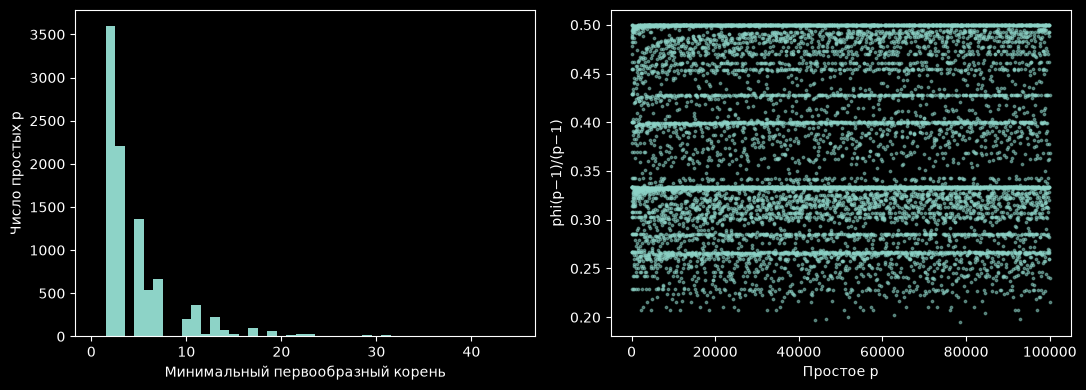

In [27]:
# Прогноз: минимальные образующие невелики (ожидаем меньше 100),
# а доля простых с образующим 2 находится около 0.37.
prime_values=[p for p in primes(10**5-1) if p>=3]
root_values=[];root_densities=[]
for p in prime_values:
    g=primitive_root(p)
    assert is_primitive_root(g,p,p-1)
    root_values.append(g)
    root_densities.append(euler_phi(p-1)/(p-1))
root_counts=Counter(root_values)
max_root=max(root_values)
max_root_primes=[p for p,g in zip(prime_values,root_values) if g==max_root]
print('Простых:',len(prime_values))
print('g=2,3,5:',[(g,root_counts[g]) for g in (2,3,5)])
print('Максимальный минимальный корень:',max_root,'при p:',max_root_primes)
print('Доля для 2:',root_counts[2]/len(prime_values),'разность с 0.3739:',root_counts[2]/len(prime_values)-.3739)
print('Минимум / максимум / среднее плотности:',min(root_densities),max(root_densities),sum(root_densities)/len(root_densities))
print('Максимальная плотность при p:',[p for p,r in zip(prime_values,root_densities) if r==max(root_densities)])
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(root_values,bins=np.arange(.5,max_root+1.5,1));axes[0].set(xlabel='Минимальный первообразный корень',ylabel='Число простых p')
axes[1].scatter(prime_values,root_densities,s=3,alpha=.5);axes[1].set(xlabel='Простое p',ylabel='phi(p−1)/(p−1)')
fig.tight_layout();plt.show()

**Ответы исследования 3.6.** Число g(p) не может быть точным квадратом для нечётного p: если g=a², то $g^{(p-1)/2}=a^{p-1}=1$, и порядок g не достигает p−1. Максимальная доля равна 1/2, поскольку p−1 чётно и формула φ(m)/m содержит множитель (1−1/2). Равенство достигается, когда у p−1 нет нечётных простых делителей, то есть p−1 — степень 2; соответствующие p выведены программой.

При независимом равномерном выборе обратимых g ожидаемое число попыток равно обратной вероятности успеха: $(p-1)/\varphi(p-1)$. При известном разложении p−1 каждая проверка использует несколько модульных степеней, а доля успеха обычно достаточна для практического поиска. Это не означает, что найденное разложение произвольного 2048-битного p−1 достаётся бесплатно. Сопоставление вычисленной доли с 0.3739 — наблюдение на конечной совокупности простых; оно не доказывает существование или значение предела и не является доказательством гипотезы Артина.

| Величина | Результат |
| --- | --- |
| Простых 3 ≤ p < 10⁵ | 9591 |
| Минимальный корень 2; 3; 5 | 3603; 2212; 1366 |
| Максимальный минимальный корень | 44 при p=71761 |
| Доля для корня 2 | 0.375664686 |
| Минимальная / максимальная плотность | 0.195569137 / 0.5 |
| Средняя плотность | 0.374292127 |


## 3.8. Криптографическое применение: дискретный логарифм

### Определение 3.7. Дискретный логарифм

Пусть $p$ — простое, $g$ — первообразный корень по модулю $p$, $h\not\equiv0\pmod p$. **Дискретным логарифмом** $h$ по основанию $g$ называется число $x$, $0\le x<p-1$, для которого

$$
g^x\equiv h\pmod p.
\tag{3.21}
$$

Вычислить $h=g^x$ по $x$ легко: `mod_pow` делает $O(L)$ умножений. Обратная задача — найти $x$ по $h$ — в общем случае считается трудной. На этой асимметрии построены протоколы Диффи—Хеллмана и Эль-Гамаля: $x$ — секретный ключ, $h=g^x$ — открытый. См. [1, §2.2, с. 62–64], [2, §10.5, с. 403–406], [4, §9.4, с. 368], [5, §11.5, с. 257–258]. Таблица степеней $2^x\bmod19$ из [5, с. 257] даёт ответ задания 3.18.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.18. Дискретный логарифм перебором

Напишите `discrete_log_bruteforce(g, h, p)`, которая перебирает $x=0,1,2,\ldots$ и возвращает первое $x$ с $g^x\equiv h$ (или `None`). Используйте последовательное умножение, а не `mod_pow` на каждом шаге.

```python
print(discrete_log_bruteforce(2, 13, 19))
print(mod_pow(2, discrete_log_bruteforce(2, 13, 19), 19))
```

Ожидаемый вывод: `5` и `13`.

</div>

In [28]:
def discrete_log_bruteforce(g,h,p):
    """Для простого p>=2 и обратимого g: минимальный x в [0,p−2] с g**x=h, либо None."""
    if p<2 or gcd(g,p)!=1: raise ValueError('Нужны p>=2 и обратимый g')
    g%=p;h%=p
    if gcd(h,p)!=1: return None
    value=1
    for x in range(p-1):
        if value==h: return x
        value=value*g%p
    return None
x=discrete_log_bruteforce(2,13,19)
assert x==5 and mod_pow(2,x,19)==13
assert discrete_log_bruteforce(4,2,7)==2
assert discrete_log_bruteforce(4,3,7) is None
print(x);print(mod_pow(2,x,19))

5
13


**Ответ 3.18.** Перед проверкой индекса x хранится $g^x\bmod p$. После проверки делается одно умножение, поэтому степень не пересчитывается с нуля. Перебор включает x=0. Если h не принадлежит порождённой g подгруппе, в диапазоне p−1 возможных показателей совпадения не будет, возвращается `None`.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 3.7. Прямая и обратная задачи

**Гипотеза.** Во сколько раз вырастет время перебора дискретного логарифма при $L\to L+4$? А время `mod_pow`?

**Ход.** Для каждого $L$ возьмите `p = random_prime(L)`, `g = primitive_root(p)`, случайный секрет $x$, $h=g^x\bmod p$. Замерьте время `mod_pow(g, x, p)` и `discrete_log_bruteforce(g, h, p)`; медиана по трём запускам.

**Часть A. Замеры.**

| $L$, бит | `mod_pow`, с | перебор, с |
|---:|---:|---:|
| 12 | | |
| 16 | | |
| 20 | | |
| 24 | | |

**Часть B. Экстраполяция.** Оцените время одного шага перебора и умножьте на среднее число шагов $\approx p/2\approx2^{L-1}$ для $L=64,\ 128,\ 2048$. Сравните с временем `mod_pow` для 2048-битного модуля (его можно замерить на простом $M_{2203}$ из исследования 3.4).

**Вопросы.**

1. Как растут два времени по $L$? Назовите это различие одним словом каждое.
2. Перебор — не лучший метод: существуют алгоритмы порядка $\sqrt p$ шагов, а для $(\mathbb Z/p\mathbb Z)^*$ — и существенно более быстрые. Как это меняет вашу оценку из части B и почему на практике используют $p$ длиной 2048 бит и более? Обзор оценок — [1, §2.6–2.7, с. 75–81], [3, §2.4.1, с. 255], [5, §11.5.1, с. 258–260].

</div>

In [29]:
# Прогноз: около 16-кратного роста перебора на каждые 4 бита,
# тогда как степень растёт полиномиально по битовой длине.
log_timings=[];log_records=[]
print('L | медиана mod_pow, с | медиана перебора, с')
for L in (12,16,20,24):
    direct=[];inverse=[]
    for _ in range(3):
        p=random_prime(L);g=primitive_root(p);x=secrets.randbelow(p-1)
        start=time.perf_counter();h=mod_pow(g,x,p);direct.append(time.perf_counter()-start)
        start=time.perf_counter();recovered=discrete_log_bruteforce(g,h,p);elapsed=time.perf_counter()-start;inverse.append(elapsed)
        assert recovered==x
        log_records.append((L,p,x,elapsed))
    log_timings.append((L,median(direct),median(inverse)))
    print(*log_timings[-1],flush=True)
log_step_seconds=median(elapsed/(x+1) for L,p,x,elapsed in log_records if L==24)
print('Средняя оценка времени проверки одного показателя:',log_step_seconds)
print('L | log10(лет) для линейного перебора')
for L in (64,128,2048):
    print(L,math.log10(log_step_seconds)+(L-1)*math.log10(2)-math.log10(365.25*86400))
L=2048;n=(1<<L)-1;a=secrets.randbelow(n-2)+2;e=random_exact_bits(L)
start=time.perf_counter();result=mod_pow(a,e,n);pow2048=time.perf_counter()-start
assert result==pow(a,e,n)
print('mod_pow, модуль ровно 2048 бит (простота не требуется), с:',pow2048)
M2203=(1<<2203)-1
start=time.perf_counter();result=mod_pow(3,random_exact_bits(2203),M2203);mersenne_pow_time=time.perf_counter()-start
print('mod_pow на простом M2203, с:',mersenne_pow_time)

L | медиана mod_pow, с | медиана перебора, с
12 1.6998965293169022e-06 4.810001701116562e-05


16 2.200016751885414e-06 0.0011381000513210893


20 2.700020559132099e-06 0.008454700000584126


24 5.100038833916187e-06 0.46613049996085465


Средняя оценка времени проверки одного показателя: 6.783465346109742e-08
L | log10(лет) для линейного перебора
64 4.297237370458779
128 23.563157092953574
2048 601.5407487677975
mod_pow, модуль ровно 2048 бит (простота не требуется), с: 0.028361400007270277
mod_pow на простом M2203, с: 0.0316585999680683


**Ответы исследования 3.7.** Прямая задача — полиномиальная по длине входа; линейный перебор логарифма — экспоненциальный. Прибавление 4 бит даёт около 16 раз для среднего числа кандидатов, но три случайных секрета дают заметный разброс; малое значение секрета особенно уменьшает время. Медианы измерены, а долгие времена выведены как log10(лет). Битовая стоимость самого шага на огромных числах выше измеренной, так что это лишь грубая модель, а не точная оценка атаки.

Универсальные методы порядка $\sqrt p$ уменьшают число шагов с $2^L$ до примерно $2^{L/2}$, но всё ещё экспоненциальны; в группе по простому модулю применимы и методы, использующие её арифметическую структуру. Поэтому практическую длину модуля выбирают по лучшим атакам, вместе с размером простого порядка подгруппы. Замерена также прямая степень для модуля ровно 2048 бит: ей не требуется простота модуля, и число $(2^{2048}-1)$ здесь не объявляется простым. Отдельно измерен известный простой M2203.

| L, бит | mod_pow, с | Логарифм перебором, с |
| --- | --- | --- |
| 12 | 1.6999e-06 | 4.81e-05 |
| 16 | 2.20002e-06 | 0.0011381 |
| 20 | 2.70002e-06 | 0.0084547 |
| 24 | 5.10004e-06 | 0.46613 |


### Почему важна структура $p-1$

Группа $(\mathbb Z/p\mathbb Z)^*$ имеет порядок $p-1$, и по разделу 3.6 в ней есть подгруппа для каждого делителя $p-1$. Если $q\mid p-1$, то возведение в степень $(p-1)/q$ переводит всю группу в подгруппу порядка $q$:

$$
h^{(p-1)/q}\equiv\bigl(g^{(p-1)/q}\bigr)^{x}\equiv\bigl(g^{(p-1)/q}\bigr)^{x\bmod q}\pmod p.
\tag{3.22}
$$

Элемент $g^{(p-1)/q}$ имеет порядок $q$, поэтому (3.22) позволяет найти **остаток $x\bmod q$** перебором всего $q$ вариантов. Если все простые делители $p-1$ малы, то, найдя остатки $x$ по каждому из них, можно восстановить $x$ целиком по КТО из ноутбука 1. Этот подход называют методом Полига—Хеллмана ([1, §2.9, теорема 2.32, с. 86–91], [3, §2.4.2, с. 258]).

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.19. Утечка секрета через малые подгруппы

1. **Один бит утекает всегда.** Возьмите $q=2$ в (3.22). Покажите, что $h^{(p-1)/2}\equiv1$ при чётном $x$ и $\equiv-1$ при нечётном. Проверьте на $p=19$, $g=2$ для всех $x$.
2. **Весь секрет.** Ниже дано простое $p=200\,560\,490\,131$ (38 бит), его первообразный корень $g=34$ и открытый ключ $h=g^x\bmod p$. Число $p-1=2\cdot3\cdot5\cdot7\cdot11\cdot13\cdot17\cdot19\cdot23\cdot29\cdot31$ раскладывается только на малые простые.
   - Для каждого $q\mid p-1$ найдите $x\bmod q$ по (3.22) перебором $q$ вариантов.
   - Восстановите $x$ по остаткам с помощью `crt` из `crypto_math`.
   - Проверьте, что `mod_pow(g, x, p) == h`.
3. Сколько всего возведений в степень вам понадобилось? Сколько шагов сделал бы `discrete_log_bruteforce` (оцените по исследованию 3.7)?

</div>

In [30]:
for x in range(18):
    h=mod_pow(2,x,19)
    assert mod_pow(h,9,19)==(1 if x%2==0 else 18)
print('Чётность показателя проверена для всех x=0..17 при p=19,g=2.')
p=200560490131;g=34;h=6960430086
assert mod_pow(g,(p-1)//2,p)==p-1
D=decompose(p-1)
assert all(e==1 for e in D.values()) and is_primitive_root(g,p,p-1)
print('Разложение p-1:',D)
residues=[];moduli=list(D);projection_powers=0;candidate_multiplications=0
for q in moduli:
    gamma=mod_pow(g,(p-1)//q,p);eta=mod_pow(h,(p-1)//q,p);projection_powers+=2
    value=1
    for r in range(q):
        if value==eta: break
        value=value*gamma%p;candidate_multiplications+=1
    else: raise AssertionError('Остаток не найден')
    residues.append(r)
    print('q =',q,'x mod q =',r)
recovered_secret=crt(residues,moduli)
assert mod_pow(g,recovered_secret,p)==h
print('Восстановленный x:',recovered_secret)
print('Степеней для проекций:',projection_powers,'+ 1 для итоговой проверки; умножений перебора:',candidate_multiplications)
print('Линейный перебор потребовал бы проверок:',recovered_secret+1,'(среднее по секрету около',(p-1)/2,')')
print('Оценка его времени по последней серии, с:',log_step_seconds*(recovered_secret+1))

Чётность показателя проверена для всех x=0..17 при p=19,g=2.
Разложение p-1: {2: 1, 3: 1, 5: 1, 7: 1, 11: 1, 13: 1, 17: 1, 19: 1, 23: 1, 29: 1, 31: 1}
q = 2 x mod q = 1
q = 3 x mod q = 0
q = 5 x mod q = 1
q = 7 x mod q = 3
q = 11 x mod q = 4
q = 13 x mod q = 1
q = 17 x mod q = 2
q = 19 x mod q = 12
q = 23 x mod q = 15
q = 29 x mod q = 27
q = 31 x mod q = 7
Восстановленный x: 108022074681
Степеней для проекций: 22 + 1 для итоговой проверки; умножений перебора: 73
Линейный перебор потребовал бы проверок: 108022074682 (среднее по секрету около 100280245065.0 )
Оценка его времени по последней серии, с: 7327.640002202255


**Ответы 3.19.** Для первообразного g в полной группе $g^{(p-1)/2}=-1$, поэтому $h^{(p-1)/2}=(-1)^x$ раскрывает чётность. Это утверждение относится к полной группе с таким образующим; в подгруппе нечётного простого порядка оно не раскрывает чётность выбранного представителя секрета.

В данном примере p−1 — произведение **различных** малых простых. Элемент $g^{(p-1)/q}$ имеет порядок q, и маленький перебор определяет x mod q. КТО восстанавливает единственный x в [0,p−1). Для основных проекций сделано 22 возведения в степень, ещё одно — для итоговой проверки. Проверка первообразности параметра использует отдельно 12 степеней; исходная дополнительная проверка квадратичного характера — ещё одну. Итого для части восстановления вместе с этими проверками — 36, не считая 36 степеней опыта о чётности (по две на каждый из 18 секретов). Поиск внутри малых подгрупп выполнен последовательным умножением, его число также выведено. При повторяющихся простых степенях простых остатков mod q недостаточно — потребовался бы полный алгоритм Полига—Хеллмана с подъёмом до q^e; здесь это не нужно.

**Восстановленный секрет:** 108022074681. Для проекций — 22 степени, внутри малых групп — 73 умножения. Прямой поиск этого секрета проверил бы 108 022 074 682 показателя.


### Безопасные простые и подгруппа простого порядка

Задание 3.19 показывает, что для дискретного логарифма важна не длина $p$, а **наибольший простой делитель** $p-1$. Отсюда стандартный выбор параметров.

Простое $p$ называется **безопасным** (*safe prime*), если $q=(p-1)/2$ тоже простое. Тогда порядок группы $p-1=2q$ и подгруппы в ней только порядков $1,2,q,2q$. Работу ведут в подгруппе порядка $q$: её образующий получается как $g=a^2\bmod p$ для любого $a\not\equiv0,\pm1$. Тогда по малой теореме Ферма (3.13) $g^q\equiv a^{p-1}\equiv1$, поэтому по (3.10) порядок $g$ делит простое $q$; а так как $g\ne1$, он равен $q$. В подгруппе простого порядка нет меньших подгрупп, и приём из задания 3.19 ничего не даёт.

В [2, §10.4.1, с. 402] протокол Диффи—Хеллмана описан именно в подгруппе простого порядка $q\mid p-1$ группы $(\mathbb Z/p\mathbb Z)^*$ (для ориентира: $p$ около 2048 бит, $q$ около 256 бит). Безопасные простые упоминаются в [2, упражнение 10.19, с. 421], а критерий первообразного корня для них — в [1, упражнение 1.33, с. 54].

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.20. Безопасное простое и мини-протокол Диффи—Хеллмана

1. Найдите наименьшее безопасное простое $p\ge10^6$: перебирайте простые $p$ функцией `next_prime` и проверяйте простоту $(p-1)/2$ функцией `is_prime_fast`. Для самопроверки: $p=1\,000\,667$.
2. Возьмите случайное $a$, $2\le a\le p-2$, и $g=a^2\bmod p$. Проверьте, что $\operatorname{ord}(g)=q$ (используйте `multiplicative_order_fast(g, p, p - 1)`).
3. **Взгляд вперёд: Диффи—Хеллман.** Алиса выбирает секрет $x_A$, Боб — секрет $x_B$ (случайные числа от $1$ до $q-1$). Они обмениваются $A=g^{x_A}$ и $B=g^{x_B}$ по открытому каналу. Вычислите $K_A=B^{x_A}$ и $K_B=A^{x_B}$ и убедитесь, что $K_A=K_B$. Объясните равенство одной строкой.
4. Какую задачу должен решить противник, видящий $p,g,A,B$, чтобы найти $K$? Почему в этой подгруппе не работает приём из задания 3.19?

Протокол Диффи—Хеллмана, его безопасность и выбор параметров подробно разбираются в отдельном ноутбуке; элементарное изложение — [5, §12.1, с. 273–275], [4, §8.6, с. 338].

</div>

In [31]:
p=next_prime(10**6-1)
while not is_prime_fast((p-1)//2): p=next_prime(p)
q=(p-1)//2
assert p==1000667 and is_prime_fast(p) and is_prime_fast(q)
a=secrets.randbelow(p-3)+2
g=mod_pow(a,2,p)
assert g!=1 and multiplicative_order_fast(g,p,p-1)==q
x_A=secrets.randbelow(q-1)+1;x_B=secrets.randbelow(q-1)+1
A=mod_pow(g,x_A,p);B=mod_pow(g,x_B,p)
K_A=mod_pow(B,x_A,p);K_B=mod_pow(A,x_B,p)
assert K_A==K_B==mod_pow(g,x_A*x_B,p)
print('Учебные p,q,a,g:',p,q,a,g)
print('Секреты учебного примера x_A,x_B:',x_A,x_B)
print('Открытые A,B:',A,B)
print('Совпавший общий секрет:',K_A)

Учебные p,q,a,g: 1000667 500333 52075 998722
Секреты учебного примера x_A,x_B: 416604 497413
Открытые A,B: 832561 739113
Совпавший общий секрет: 464968


**Ответы 3.20.** Наименьшее безопасное простое p≥10⁶ — 1 000 667, q=500 333. Для a∉{0,±1} квадрат g=a² не равен 1, а $g^q=1$, поэтому его порядок — простое q. Равенство ключей следует из $(g^{x_B})^{x_A}=(g^{x_A})^{x_B}=g^{x_Ax_B}$.

Прямая задача противника — вычислительная задача Диффи—Хеллмана: получить $g^{x_Ax_B}$ из g,A,B. Решение дискретного логарифма одного открытого ключа достаточно для атаки, но это не утверждение об эквивалентности двух задач. Порядок рабочей подгруппы прост и велик относительно учебного примера: проекция по малым простым делителям p−1 не разбивает секрет на много маленьких остатков, а проекция в порядок 2 даёт 1 для всех её элементов. Эти маленькие численные параметры предназначены для опыта и не обеспечивают реальную криптографическую стойкость.

## 3.9. Перенос в `crypto_math`

Часть функций ноутбука понадобится в ноутбуках о Диффи—Хеллмане, Эль-Гамале и RSA. Перенесём их в библиотеку курса; класс `ZnZ` остаётся учебным инструментом этого ноутбука.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3.21. Пополнение библиотеки

1. Перенесите в `crypto_math/number_theory.py` функции

   `smallest_factor`, `decompose`, `euler_phi`, `multiplicative_order_fast` (под именем `multiplicative_order`), `is_primitive_root`, `primitive_root`.

   Функция `euler_phi` в библиотеке может вычисляться прямо через `decompose`, без `mult_function`.
2. Добавьте в `tests/test_number_theory.py` по одной проверке свойств: `recompose(decompose(n)) == n`; $a^{\varphi(n)}\equiv1$ для случайных обратимых $a$; `multiplicative_order(a, n)` делит `euler_phi(n)`; $\sum_{d\mid n}\varphi(d)=n$.
3. Перезапустите kernel и убедитесь, что функции импортируются из `crypto_math`.

</div>

In [32]:
import subprocess,sys
import crypto_math
from crypto_math import number_theory as nt
for n in range(1,1001):
    assert nt.decompose(n)==decompose(n)
    assert nt.recompose(nt.decompose(n))==n
    assert nt.euler_phi(n)==euler_phi(n)
for n in range(2,101):
    assert nt.primitive_root(n)==primitive_root(n)
    for a in ZnZ(n).elems(): assert nt.multiplicative_order(a,n)==multiplicative_order_fast(a,n)
fresh=subprocess.run([sys.executable,'-c','import crypto_math; from crypto_math import decompose, euler_phi, multiplicative_order, primitive_root; assert decompose(100)=={2:2,5:2}; assert euler_phi(9)==6; assert multiplicative_order(5,17)==16; assert primitive_root(19)==2; print(crypto_math.__file__)'],capture_output=True,text=True)
print('Импорт в новом процессе:',fresh.stdout)
assert fresh.returncode==0,fresh.stderr
result=subprocess.run([sys.executable,'-m','pytest','-q'],capture_output=True,text=True)
print(result.stdout)
if result.returncode: print(result.stderr)
assert result.returncode==0

Импорт в новом процессе: C:\Users\нагибатор\PycharmProjects\PythonProject5\app\crypto_math\__init__.py



.......................                                                  [100%]
23 passed in 1.56s



**Выполнено 3.21.** Новые функции добавлены в `number_theory.py`, быстрая версия порядка экспортируется под именем `multiplicative_order`. Для теста восстановления туда же добавлена `recompose`; `euler_phi` вычисляет произведение напрямую, без замыкания `mult_function`. Публичные импорты обновлены. Класс `ZnZ`, наивные методы, исследования и графики остались в ноутбуке. Свойства разложения, теоремы Эйлера, минимальности порядка, суммы φ по делителям и первообразных корней проверяются общими тестами. Новый процесс Python проверяет импорт без использования состояния текущего ядра.

### Сверка с SageMath

Ячейку ниже выполните в ноутбуке с ядром **SageMath 10.x** после переноса функций. В обычном ядре Python ячейка лишь сообщит, что Sage недоступен.

In [33]:
import random

try:
    from sage.all import (
        factor as sage_factor,
        euler_phi as sage_euler_phi,
        Mod as sage_Mod,
        primitive_root as sage_primitive_root,
        is_prime as sage_is_prime,
    )
except ImportError:
    sage_available = False
else:
    sage_available = True

if not sage_available:
    print("SageMath недоступен в этом ядре. Переключите ядро на SageMath 10.x и выполните ячейку снова.")
else:
    from crypto_math.number_theory import (
        decompose, euler_phi, multiplicative_order, primitive_root, gcd,
    )

    rng = random.Random(2026)
    for _ in range(int(300)):
        n = rng.randrange(2, int(10) ** int(9))
        assert decompose(n) == {int(p): int(e) for p, e in sage_factor(n)}
        assert euler_phi(n) == int(sage_euler_phi(n))
        a = rng.randrange(1, n)
        if gcd(a, n) == 1 and n < int(10) ** int(6):
            assert multiplicative_order(a, n) == int(sage_Mod(a, n).multiplicative_order())

    for p in range(int(3), int(20000)):
        if sage_is_prime(p):
            g = primitive_root(p)
            assert int(sage_Mod(g, p).multiplicative_order()) == p - 1
            # Sage возвращает некоторый первообразный корень; наш — наименьший
            assert g <= int(sage_primitive_root(p))

    print("Сверка с SageMath пройдена.")

SageMath недоступен в этом ядре. Переключите ядро на SageMath 10.x и выполните ячейку снова.


<div style="background-color: #342d43; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Итоги ноутбука 3

**Что вычисляется быстро** (полиномиально по $L$):

- возведение в степень и обратный элемент — двумя способами (раздел 3.4);
- порядок элемента и проверка первообразного корня — **если известно разложение** порядка группы (разделы 3.5, 3.7).

**Что требует перебора** (экспоненциально по $L$ для изученных методов):

- разложение $n=pq$ и, как следствие, вычисление $\varphi(n)$ (разделы 3.1, 3.3);
- дискретный логарифм в $(\mathbb Z/p\mathbb Z)^*$ (раздел 3.8).

**Что из этого следует для криптографии:**

$$
\text{RSA}\leftarrow\text{трудность разложения } n=pq,\qquad
\text{DH, Эль-Гамаль}\leftarrow\text{трудность дискретного логарифма}.
$$

Параметры выбирают так, чтобы у «быстрых» алгоритмов было всё нужное (известно разложение $p-1$), а у противника — нет (подгруппа большого простого порядка).

**Пополнение `crypto_math/number_theory.py`** (в начале ноутбука — `is_prime_fast`, `primes`, `next_prime` из ноутбука 2; в конце — функции этого ноутбука):

```text
smallest_factor()   decompose()   euler_phi()
multiplicative_order()   is_primitive_root()   primitive_root()
```

**Дальше — ноутбук 4:** тест Ферма как следствие теоремы 3.1, числа Кармайкла, тест Миллера—Рабина, числа Мерсенна и генерация больших простых чисел.

</div>

## 3.10. Литература

### Основная литература

Ссылки в тексте ноутбука даны в виде [номер, раздел, страницы].

1. Hoffstein J., Pipher J., Silverman J. H. *An Introduction to Mathematical Cryptography*. — New York : Springer, 2008 (1st ed.). Страницы указаны по первому изданию.
   - §1.3, с. 22 — функция Эйлера и группа $(\mathbb Z/m\mathbb Z)^*$; теорема 1.21, с. 27 — основная теорема арифметики;
   - теорема 1.25, с. 30 — малая теорема Ферма; предложение 1.30, с. 32 — порядок делит $p-1$; §1.5, теорема 1.31, с. 33–34 — первообразные корни и их число $\varphi(p-1)$;
   - упражнения 1.31–1.33, с. 53–54 — элемент порядка $q$, первообразные корни, безопасные простые;
   - §2.2–2.3, с. 62–68 — задача дискретного логарифма и протокол Диффи—Хеллмана; предложение 2.14, с. 74 — теорема Лагранжа;
   - §2.6–2.7, с. 75–81 — трудность дискретного логарифма, перебор (предложение 2.20) и «шаг младенца — шаг великана»;
   - §2.9, с. 86–91 — алгоритм Полига—Хеллмана (теорема 2.32);
   - теорема 3.1, с. 114 — формула Эйлера для $pq$; замечание 3.10, с. 121–122 — знание $(p-1)(q-1)$ равносильно разложению $N=pq$.
2. Boneh D., Shoup V. *A Graduate Course in Applied Cryptography*. — Version 0.4, 2017.
   - §10.4, с. 401–402 — протокол Диффи—Хеллмана в подгруппе простого порядка $q\mid p-1$;
   - §10.5, с. 403–408 — предположение о трудности дискретного логарифма; пример подгруппы простого порядка в $\mathbb Z_p^*$;
   - упражнение 10.19, с. 421 — безопасные простые ($q=(p-1)/2$ простое);
   - приложение A.2.2, с. 815 — цикличность $\mathbb Z_p^*$, порядок, теорема Лагранжа, вычисление порядка при известном разложении $p-1$.
3. Yan S. Y. *Number Theory for Computing*. — 2nd ed. — Berlin : Springer, 2002.
   - теорема 1.2.8, с. 28 — основная теорема арифметики;
   - §1.4.1–1.4.2, с. 63–69 — мультипликативные функции, $\tau(n)$, $\sigma(n)$; теорема 1.4.10, с. 72–73 — чётные совершенные числа;
   - §1.4.4, с. 78–81 — функции Эйлера и Кармайкла;
   - теоремы 1.6.15–1.6.17, с. 125–127 — теоремы Ферма, Эйлера и Кармайкла;
   - §1.6.7, с. 150–155 — порядок и первообразные корни: свойства порядка (теорема 1.6.31), примеры для $n=34, 46$, упражнение о втором первообразном корне по модулю $106$, таблица 1.21 наименьших первообразных корней для $n\le1017$, критерий существования (теорема 1.6.35), гипотеза Артина;
   - §2.3.2, с. 232 — пробное деление; §2.4.1–2.4.2, с. 255–258 — алгоритмы «шаг младенца — шаг великана» и Сильвера—Полига—Хеллмана.

4. Rosen K. H. *Elementary Number Theory and Its Applications*. — 6th ed. — Boston : Addison-Wesley (Pearson), 2011.
   - §6.3, теорема 6.14, с. 234–236 — теорема Эйлера; §7.1–7.2, с. 239–253 — функция Эйлера (теоремы 7.4–7.5, тождество 7.7), $\tau$ и $\sigma$; §7.3, с. 256–260 — совершенные числа, тест Люка—Лемера;
   - §8.6, с. 338 — протокол Диффи—Хеллмана;
   - §9.1–9.3, с. 347–367 — порядок (теоремы 9.1, 9.4), число элементов порядка $d$ (теорема 9.8), гипотеза Артина (с. 357), критерий существования первообразного корня (теорема 9.15);
   - §9.4, с. 368–377 — дискретные логарифмы (индексы); §9.6, с. 385–389 — минимальный универсальный показатель $\lambda(n)$.
5. Kraft J. S., Washington L. C. *An Introduction to Number Theory with Cryptography*. — 2nd ed. — Boca Raton : CRC Press, 2018.
   - §8.1–8.2, с. 189–197 — теоремы Ферма и Эйлера, функция $\varphi$;
   - §11.1–11.2, с. 239–249 — порядок и первообразные корни, критерий (предложение 11.11); §11.5, с. 257–262 — дискретный логарифм, «шаг младенца — шаг великана»; §11.6, с. 263–266 — существование первообразных корней;
   - §12.1, с. 273–275 — протокол Диффи—Хеллмана; §14.1, с. 319 — пробное деление.
6. Herkommer M. A. *Number Theory: A Programmer's Guide*. — New York : McGraw-Hill, 1999.
   - §3.0–3.4, с. 49–69 — разложение пробным делением, $\varphi$ подсчётом НОД и через разложение, $\tau$, $\sigma$ (программы на C);
   - §4.4, с. 96–101 — порядок и первообразные корни (программа таблицы порядков).
7. Weissman M. H. *An Illustrated Theory of Numbers*. — Providence, RI : AMS, 2017; сопровождающий ноутбук P3wNT Notebook 4 — источник разделов 3.1–3.2.

### Дополнительная литература

8. Shoup V. *A Computational Introduction to Number Theory and Algebra*. — 2nd ed. — Cambridge University Press, 2009.
9. Мартынов Л. М. *Алгебра и теория чисел для криптографии* : учебное пособие. — СПб. : Лань, 2020.
10. Рябко Б. Я., Фионов А. Н. *Криптографические методы защиты информации* : учебное пособие для вузов. — М. : Горячая линия—Телеком, 2005.
11. [SageMath Reference Manual: Elementary Number Theory](https://doc.sagemath.org/html/en/reference/rings_standard/).